In [1]:
pip install pycocotools

Note: you may need to restart the kernel to use updated packages.


In [2]:
# =============================
# CONFIG
# =============================
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import torch
import os

os.environ['ALBUMENTATIONS_DISABLE_CHECKING_VERSION'] = '1'

DATASET_TYPE = 'COCO'

NUM_EPOCHS = 5
CHECKPOINT_FILE = "/kaggle/input/"
NUM_IMAGES = None
LOAD_MODEL = False   

NEED_TO_CHANGE_LR = True
SCHEDULER_STEP = 5
MODEL_NAME = "YOLO_V1_wth blocks"

PATH = "/kaggle/input/datasets/awsaf49/coco-2017-dataset/coco2017"

ANCHORS = [
    [(0.28, 0.22), (0.38, 0.48), (0.9, 0.78)],
    [(0.07, 0.15), (0.15, 0.11), (0.14, 0.29)],
    [(0.02, 0.03), (0.04, 0.07), (0.08, 0.06)],
]

IMAGE_SIZE = 416
SIZES = [13, 26, 52]
GRID_SIZES = [IMAGE_SIZE // 32, IMAGE_SIZE // 16, IMAGE_SIZE // 8]
BATCH_SIZE = 32
NUM_WORKERS = 0
PIN_MEMORY = True

BACKBONE_NUM_CHANNELS = [128, 256, 512]
NUMBER_BLOCKS_LIST = [3, 4, 6, 3]
LEARNING_RATE = 1e-4

CONF_THRESHOLD = 0.5

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

scale = 1.2

TRAIN_TRANSFORMS = A.Compose(
    [
        A.LongestMaxSize(max_size=int(IMAGE_SIZE * scale)),
        A.PadIfNeeded(
            min_height=int(IMAGE_SIZE * scale),
            min_width=int(IMAGE_SIZE * scale),
            border_mode=cv2.BORDER_CONSTANT,
            value=[0, 0, 0],
            p=1.0
        ),
        A.RandomCrop(width=IMAGE_SIZE, height=IMAGE_SIZE),
        A.ColorJitter(brightness=0.6, contrast=0.6, saturation=0.6, hue=0.6, p=0.4),
        A.OneOf(
            [
                A.ShiftScaleRotate(rotate_limit=20, p=0.5, border_mode=cv2.BORDER_CONSTANT),
                A.Affine(shear=15, p=0.5, mode=0),
            ],
            p=1.0,
        ),
        A.HorizontalFlip(p=0.5),
        A.Blur(p=0.1),
        A.CLAHE(p=0.1),
        A.Posterize(p=0.1),
        A.ToGray(p=0.1),
        A.ChannelShuffle(p=0.05),
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1], max_pixel_value=255,),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(format="yolo", min_visibility=0.4, label_fields=[],),
)
TEST_TRANSFORMS = A.Compose(
    [
        A.LongestMaxSize(max_size=IMAGE_SIZE),
        A.PadIfNeeded(
            min_height=IMAGE_SIZE,
            min_width=IMAGE_SIZE,
            border_mode=cv2.BORDER_CONSTANT,
            value=[0, 0, 0],
            p=1.0
        ),
        A.Normalize(mean=[0, 0, 0], std=[1, 1, 1], max_pixel_value=255,),
        ToTensorV2(),
    ],
    bbox_params=A.BboxParams(format="yolo", min_visibility=0.4, label_fields=[]),
)

COCO_CLASSES = ['person','bicycle','car','motorcycle','airplane','bus','train','truck','boat',
 'traffic light','fire hydrant','stop sign','parking meter','bench','bird','cat','dog','horse',
 'sheep','cow','elephant','bear','zebra','giraffe','backpack','umbrella','handbag','tie',
 'suitcase','frisbee','skis','snowboard','sports ball','kite','baseball bat','baseball glove',
 'skateboard','surfboard','tennis racket','bottle','wine glass','cup','fork','knife','spoon',
 'bowl','banana','apple','sandwich','orange','broccoli','carrot','hot dog','pizza','donut',
 'cake','chair','couch','potted plant','bed','dining table','toilet','tv','laptop','mouse',
 'remote','keyboard','cell phone','microwave','oven','toaster','sink','refrigerator','book',
 'clock','vase','scissors','teddy bear','hair drier','toothbrush']

NUM_CLASSES = 80

COCO_original_classes_to_list_idx = {
    1:0,2:1,3:2,4:3,5:4,6:5,7:6,8:7,9:8,10:9,11:10,13:11,14:12,15:13,16:14,17:15,18:16,
    19:17,20:18,21:19,22:20,23:21,24:22,25:23,27:24,28:25,31:26,32:27,33:28,34:29,35:30,
    36:31,37:32,38:33,39:34,40:35,41:36,42:37,43:38,44:39,46:40,47:41,48:42,49:43,50:44,
    51:45,52:46,53:47,54:48,55:49,56:50,57:51,58:52,59:53,60:54,61:55,62:56,63:57,64:58,
    65:59,67:60,70:61,72:62,73:63,74:64,75:65,76:66,77:67,78:68,79:69,80:70,81:71,82:72,
    84:73,85:74,86:75,87:76,88:77,89:78,90:79}


/tmp/ipykernel_24/2071071061.py:51: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(
/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_24/2071071061.py:63: UserWarning: Argument(s) 'mode' are not valid for transform Affine
  A.Affine(shear=15, p=0.5, mode=0),
/tmp/ipykernel_24/2071071061.py:81: UserWarning: Argument(s) 'value' are not valid for transform PadIfNeeded
  A.PadIfNeeded(


In [3]:
#============================
# YOLO MODEL
#============================
import torch 
from torch import nn 

num_anchors = len(ANCHORS[0])

# Defining CNN Block 
class CNNBlock(nn.Module): 
	def __init__(self, in_channels, out_channels, use_batch_norm=True, **kwargs): 
		super().__init__() 
		self.conv = nn.Conv2d(in_channels, out_channels, bias=not use_batch_norm, **kwargs) 
		self.bn = nn.BatchNorm2d(out_channels) 
		self.activation = nn.LeakyReLU(0.1) 
		self.use_batch_norm = use_batch_norm 

	def forward(self, x): 
		# Applying convolution 
		x = self.conv(x) 
		# Applying BatchNorm and activation if needed 
		if self.use_batch_norm: 
			x = self.bn(x) 
			return self.activation(x) 
		else: 
			return x
		

# Defining residual block 
class ResidualBlock(nn.Module): 
	def __init__(self, channels, use_residual=True, num_repeats=1): 
		super().__init__() 
		
		# Defining all the layers in a list and adding them based on number of 
		# repeats mentioned in the design 
		res_layers = [] 
		for _ in range(num_repeats): 
			res_layers += [ 
				nn.Sequential( 
					nn.Conv2d(channels, channels // 2, kernel_size=1), 
					nn.BatchNorm2d(channels // 2), 
					nn.LeakyReLU(0.1), 
					nn.Conv2d(channels // 2, channels, kernel_size=3, padding=1), 
					nn.BatchNorm2d(channels), 
					nn.LeakyReLU(0.1) 
				) 
			] 
		self.layers = nn.ModuleList(res_layers) 
		self.use_residual = use_residual 
		self.num_repeats = num_repeats 
	
	# Defining forward pass 
	def forward(self, x): 
		for layer in self.layers: 
			residual = x 
			x = layer(x) 
			if self.use_residual: 
				x = x + residual 
		return x


# Defining scale prediction class 
class Head(nn.Module): 
	
	def __init__(self, in_channels, num_classes): 
		super().__init__() 
		# Defining the layers in the network 
		self.features = nn.Sequential( 
			nn.Conv2d(in_channels, 2*in_channels, kernel_size=3, padding=1), 
			nn.BatchNorm2d(2*in_channels), 
			nn.LeakyReLU(0.1)			
		) 
		self.pred_layer = nn.Conv2d(2*in_channels, (num_classes + 5) * 3, kernel_size=1)
		self.num_classes = num_classes 
	
	# Defining the forward pass and reshaping the output to the desired output 
	# format: (batch_size, 3, grid_size, grid_size, num_classes + 5) 
	def forward(self, x): 
		output = self.features(x) 
		output = self.pred_layer(output)
		output = output.view(x.size(0), 3, self.num_classes + 5, x.size(2), x.size(3)) 
		output = output.permute(0, 1, 3, 4, 2) 
		return output


class Backbone(nn.Module):
        # output_1 - 256, output_2 - 512  output_3 - 1024	
	
    def __init__(self, in_channels=3):
        super().__init__()
        self.initial_conv = nn.Sequential(
            CNNBlock(in_channels, 32, kernel_size=3, stride=1, padding=1),
            CNNBlock(32, 64, kernel_size=3, stride=2, padding=1)
        )
        
        self.block1 = nn.Sequential(
            ResidualBlock(64, num_repeats=1),
            CNNBlock(64, 128, kernel_size=3, stride=2, padding=1),
            ResidualBlock(128, num_repeats=2)
        )
        
        self.block2 = nn.Sequential(
            CNNBlock(128, 256, kernel_size=3, stride=2, padding=1),
            ResidualBlock(256, num_repeats=8)
        )
        
        self.block3 = nn.Sequential(
            CNNBlock(256, 512, kernel_size=3, stride=2, padding=1),
            ResidualBlock(512, num_repeats=8)
        )
        
        self.block4 = nn.Sequential(
            CNNBlock(512, 1024, kernel_size=3, stride=2, padding=1),
            ResidualBlock(1024, num_repeats=4)
        )

    def forward(self, x):
        x1 = self.initial_conv(x)
        x2 = self.block1(x1)
        x3 = self.block2(x2) #256 # First route connection
        x4 = self.block3(x3) #512 # Second route connection
        x5 = self.block4(x4) #1024
        return x3, x4, x5




class Neck(nn.Module):
    def __init__(self):
        # """ifif"""
        super().__init__()
        self.block_1 = nn.Sequential(
			CNNBlock(1024, 512, kernel_size=1, stride=1, padding=0),
			CNNBlock(512, 1024, kernel_size=3, stride=1, padding=1),
			ResidualBlock(1024, use_residual=False, num_repeats=1),
			CNNBlock(1024, 512, kernel_size=1, stride=1, padding=0),
			
        )
		
        self.resize_1 = CNNBlock(512, 256, kernel_size=1, stride=1, padding=0)
        self.resize_2 = CNNBlock(256, 128, kernel_size=1, stride=1, padding=0) 
        
        # ===================================================
        self.block_2 = nn.Sequential(
            
            CNNBlock(768, 256, kernel_size=1, stride=1, padding=0), 
            CNNBlock(256, 512, kernel_size=3, stride=1, padding=1), 
            ResidualBlock(512, use_residual=False, num_repeats=1), 
            CNNBlock(512, 256, kernel_size=1, stride=1, padding=0), 
        )
        
        
        # ===================================================
        self.block_3 = nn.Sequential(
            
            
            CNNBlock(384, 128, kernel_size=1, stride=1, padding=0), 
            CNNBlock(128, 256, kernel_size=3, stride=1, padding=1), 
            ResidualBlock(256, use_residual=False, num_repeats=1), 
            CNNBlock(256, 128, kernel_size=1, stride=1, padding=0)
            )
        self.upsample = nn.Upsample(scale_factor=2)

    def forward(self, route_1, route_2, route_3):
        # input: route_1 = 256, route_2 = 512, route_3 = 1024
        # print("neck, route", route_1.shape, route_2.shape, route_3.shape)
        # =========
        #block_1
        #==========
        x = self.block_1(route_3) # возвращает 512
        output_1 = x.clone()
        # print("neck, block_1", x.shape)
        # =========
        #block_2
        #==========
        x = self.resize_1(x)    # возвращает 256
        x = self.upsample(x)    # увеличивает размер в 2 раза       
        # print("neck, block_2, upsample", x.shape)		
        x = torch.cat([x, route_2], dim=1) 
        # print("neck, block_2 after cat", x.shape)
        x = self.block_2(x) # возвращает 256
        output_2 = x.clone()
        # print("neck, block_2", x.shape)
        # =========
        #block_2
        #==========
        x = self.resize_2(x) # возвращает 128
        x = self.upsample(x) # увеличивает размер в 2 раза
        # print("neck, block_3, upsample", x.shape)
        x = torch.cat([x, route_1], dim=1)
        # print("neck, block_3 after cat", x.shape)
        output_3 = self.block_3(x) # возвращает 128
        # print("neck, block_3", x.shape)

        
        return output_1, output_2, output_3
		

        
	

class YOLO(nn.Module):
	def __init__(self, in_channels=3, num_classes=20):
		super().__init__()
		self.num_classes = num_classes 
		self.in_channels = in_channels

		self.backbone = Backbone(in_channels)
		self.neck = Neck()

		self.head1 = Head(512, num_classes=num_classes)

		self.head2 = Head(256, num_classes=num_classes)

		self.head3 = Head(128, num_classes=num_classes)

		self.upsample = nn.Upsample(scale_factor=2)

	def forward(self, x):
	
		route_1, route_2, route_3 = self.backbone(x) #256, 512, 1024

		neck_out_1, neck_out_2, neck_out_3 = self.neck(route_1, route_2, route_3) #512, 256, 

		head1_out = self.head1(neck_out_1)
		head2_out = self.head2(neck_out_2)
		head3_out = self.head3(neck_out_3)

		return [head1_out, head2_out, head3_out]
	



In [4]:
#========================
#      UTILS
#========================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import os
import random
import torch
from torch import nn
from torch.optim import Adam
import torchvision.ops as ops
from collections import Counter


def iou(box1, box2, is_pred=True):
    if is_pred:
        b1_x1 = box1[..., 0:1] - box1[..., 2:3] / 2
        b1_y1 = box1[..., 1:2] - box1[..., 3:4] / 2
        b1_x2 = box1[..., 0:1] + box1[..., 2:3] / 2
        b1_y2 = box1[..., 1:2] + box1[..., 3:4] / 2
        b2_x1 = box2[..., 0:1] - box2[..., 2:3] / 2
        b2_y1 = box2[..., 1:2] - box2[..., 3:4] / 2
        b2_x2 = box2[..., 0:1] + box2[..., 2:3] / 2
        b2_y2 = box2[..., 1:2] + box2[..., 3:4] / 2
        x1 = torch.max(b1_x1, b2_x1)
        y1 = torch.max(b1_y1, b2_y1)
        x2 = torch.min(b1_x2, b2_x2)
        y2 = torch.min(b1_y2, b2_y2)
        intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
        box1_area = abs((b1_x2 - b1_x1) * (b1_y2 - b1_y1))
        box2_area = abs((b2_x2 - b2_x1) * (b2_y2 - b2_y1))
        union = box1_area + box2_area - intersection
        return intersection / (union + 1e-6)
    else:
        intersection_area = torch.min(box1[..., 0], box2[..., 0]) * torch.min(box1[..., 1], box2[..., 1])
        box1_area = box1[..., 0] * box1[..., 1]
        box2_area = box2[..., 0] * box2[..., 1]
        union_area = box1_area + box2_area - intersection_area
        return intersection_area / union_area


def custom_nms(bboxes, iou_threshold, threshold):
    mask = bboxes[..., 1] > threshold
    bboxes = bboxes[mask].tolist()
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)
    bboxes_nms = []
    while bboxes:
        first_box = bboxes.pop(0)
        for box in bboxes:
            if (box[0] != first_box[0]
                or iou(torch.tensor(first_box[2:]), torch.tensor(box[2:])) < iou_threshold):
                if box not in bboxes_nms:
                    bboxes_nms.append(box)
    return bboxes_nms


def convert_cells_to_bboxes(input_boxes, anchors, size: float, is_predictions=True) -> torch.Tensor:
    batch_size = input_boxes.shape[0]
    num_anchors = len(anchors)
    box_predictions = input_boxes[..., 1:5]
    if is_predictions:
        anchors = anchors.reshape(1, len(anchors), 1, 1, 2)
        box_predictions[..., 0:2] = torch.sigmoid(box_predictions[..., 0:2])
        box_predictions[..., 2:] = torch.exp(box_predictions[..., 2:]) * anchors
        scores = torch.sigmoid(input_boxes[..., 0:1])
        best_class = torch.argmax(input_boxes[..., 5:], dim=-1).unsqueeze(-1)
    else:
        scores = input_boxes[..., 0:1]
        best_class = input_boxes[..., 5:6]
    cell_indices_X = torch.arange(size).view(1,1,size,1,1).expand(batch_size, num_anchors, size, size, 1).to(DEVICE)
    cell_indices_Y = torch.arange(size).view(1,1,1,size,1).expand(batch_size, num_anchors, size, size, 1).to(DEVICE)
    x = 1 / size * (box_predictions[..., 0:1] + cell_indices_X)
    y = 1 / size * (box_predictions[..., 1:2] + cell_indices_Y)
    width_height = 1 / size * box_predictions[..., 2:4]
    converted_bboxes = torch.cat((scores, x, y, width_height, best_class), dim=-1).reshape(batch_size, num_anchors * size * size, 6)
    return converted_bboxes


def get_true_bboxes(input_bboxes, iou_threshold, scaled_anchors, conf_threshold, is_preds=True):
    all_boxes_list = []
    batch_size = input_bboxes[0].shape[0]
    all_bboxes = torch.Tensor().to(DEVICE)
    for i in range(len(input_bboxes)):
        size = input_bboxes[i].shape[2]
        converted_boxes = convert_cells_to_bboxes(input_bboxes[i].to(DEVICE), anchors=scaled_anchors[i], size=size, is_predictions=is_preds)
        all_bboxes = torch.cat((all_bboxes, converted_boxes), dim=1)
    all_bboxes[..., 1:5] = xywh2xyxy(all_bboxes[..., 1:5])
    for i in range(batch_size):
        one_img_boxes = all_bboxes[i].detach().to()
        conf_mask = one_img_boxes[..., 0] >= conf_threshold
        one_img_boxes = one_img_boxes[conf_mask]
        img_boxes = one_img_boxes[..., 1:5]
        img_scores = one_img_boxes[..., 0]
        class_ids = one_img_boxes[..., 5:].squeeze(-1)
        keep_indices = ops.batched_nms(boxes=img_boxes, scores=img_scores, idxs=class_ids, iou_threshold=iou_threshold)
        all_boxes_list.append(one_img_boxes[keep_indices])
    return all_boxes_list


def save_checkpoint(model, optimizer, model_epoch, dataset_type: str, filename="my_checkpoint.pt"):
    print("=> Saving checkpoint")
    checkpoint = {
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "epoch": model_epoch,
        "model_dataset_type": dataset_type
    }
    torch.save(checkpoint, filename)


def load_pretrained_model(checkpoint_path: str, model, optimizer, lr, model_epoch_list):
    """Load pretrained COCO model checkpoint."""
    checkpoint = torch.load(checkpoint_path, map_location=torch.device('cpu'))
    print(f"=> Loading model from {checkpoint_path}")
    model.load_state_dict(checkpoint["state_dict"])
    if len(checkpoint["optimizer"]["param_groups"]) == 1:
        optimizer.load_state_dict(checkpoint["optimizer"])
    else:
        optimizer = Adam([
            {'params': model.backbone.parameters(), 'lr': LEARNING_RATE * 0.5},
            {'params': model.head1.pred_layer.parameters(), 'lr': LEARNING_RATE},
            {'params': model.head2.pred_layer.parameters(), 'lr': LEARNING_RATE},
            {'params': model.head3.pred_layer.parameters(), 'lr': LEARNING_RATE}
        ])
    model_epoch_list.append(checkpoint["epoch"])
    for state in optimizer.state.values():
        for k, v in state.items():
            if isinstance(v, torch.Tensor):
                state[k] = v.to(DEVICE)
    return model, optimizer


def xywh2xyxy(bboxes: torch.Tensor, box_format: str = "midpoint") -> torch.Tensor:
    if box_format == "midpoint":
        box_x1 = bboxes[..., 0:1] - bboxes[..., 2:3] / 2
        box_y1 = bboxes[..., 1:2] - bboxes[..., 3:4] / 2
        box_x2 = bboxes[..., 0:1] + bboxes[..., 2:3] / 2
        box_y2 = bboxes[..., 1:2] + bboxes[..., 3:4] / 2
    return torch.cat([box_x1, box_y1, box_x2, box_y2], dim=-1)


In [5]:

#=========================
#COCO DATASET
#=========================

import numpy as np
import os
import pandas as pd
import torch
from torch.utils.data import Dataset
from pycocotools.coco import COCO
import pickle

from PIL import Image



class CachedCOCO:
    """ 
    COCO.
    """
    def __init__(self, annotation_path):
        self.annotation_path = annotation_path
        self.cache_path = annotation_path + '.pickle'
        self.coco = self._load_coco()
        
    def _load_coco(self):
        if os.path.exists(self.cache_path):
            # Загружаем из кэша
            with open(self.cache_path, 'rb') as f:
                return pickle.load(f)
        
        # Создаем новый объект COCO
        coco = COCO(self.annotation_path)
        
        # Сохраняем в кэш
        with open(self.cache_path, 'wb') as f:
            pickle.dump(coco, f)
            
        return coco
    
    def __getattr__(self, name):
        return getattr(self.coco, name)

        
class COCOYOLODataset(Dataset):
    """
    A custom dataset class for YOLO object detection on the COCO dataset.
    

    """

    def __init__(self, dir_path, anchors: list, scales: list, train=True, transform=None, num_images=None, input_coco=None):
        """
        Initialize the dataset.
        
        :param dir_path: Path to the dataset directory
        :param anchors: List of anchor box dimensions for each scale
        :param scales: List of output scales (e.g., [13, 26, 52])
        :param train: Whether to use training or testing data
        :param transform: Optional transformations to apply to images and bounding boxes
        :param num_images: Number of images to load (None for all)
        """
         
        super().__init__()
        
         # Validate that anchors and scales have the same length
        try:
            len(anchors) == len(scales)
        except:
            print("Anchors and scales must have the same length")

        self.dir_path = dir_path

        if train:
            self.annotation_path = os.path.join(dir_path, "annotations/instances_train2017.json")
            self.image_dir = os.path.join(dir_path, "train2017")
        else:
            self.annotation_path = os.path.join(dir_path, "annotations/instances_val2017.json")
            self.image_dir = os.path.join(dir_path, "val2017")
        
        # Инициализируем coco API если не передался 
        self.coco = COCO(self.annotation_path)

        # Получаем список изображений и их id (list)
        self.img_ids= self.coco.getImgIds()
        
        # !!!!!!!!!!!!!!!!!!!!!!!
        # Отфильтруем изображения в которых нет аннотаций
        self.img_ids = [
            img_id for img_id in self.img_ids 
            if len(self.coco.getAnnIds(imgIds=img_id)) > 0
        ]

        # Если передали количество изображений, то ограничиваем список изображений
        if num_images is not None:
            self.img_ids = self.img_ids[:num_images]
        
        self.transform = transform
        
        # Flatten and convert anchors to tensor
        self.anchors = torch.tensor(anchors)
        self.scales = scales
        
        # Set up anchor and scale properties
        self.num_anchor_in_scale = len(anchors[0])
        self.scale_numbers = len(self.scales)
        

    def __len__(self):
        """Return the number of images in the dataset."""
        return len(self.img_ids)
    
    def _convert_original_class_to_list_idx(self, original_class_id):
        
        return COCO_original_classes_to_list_idx[original_class_id]

    def _load_image_and_boxes(self, idx: int ):
        # Получим id изображения
        img_id = self.img_ids[idx]
        # Получим изображение и его параметры в формате list(dict): {'license': 3,
                    #   'file_name': '000000184613.jpg',
                    #   'coco_url': 'http://images.cocodataset.org/train2017/000000184613.jpg',
                    #   'height': 336,
                    #   'width': 500,
                    #   'date_captured': '2013-11-14 12:36:29',
                    #   'flickr_url': 'http://farm3.staticflickr.com/2169/2118578392_1193aa04a0_z.jpg',
                    #   'id': 184613}]
        img_info = self.coco.loadImgs(img_id)
        img_width = img_info[0]['width']
        img_height = img_info[0]['height']
        image_path = os.path.join(self.image_dir, img_info[0]['file_name'])


        # Получим ids аннотаций к изображению
        anns_ids = self.coco.getAnnIds(imgIds=img_id)
        # Получим аннотации к изображению list[dict]
        # аннотации заданы в формате: {....,"category_id": xxx, 'bbox':[xmin, ymin, w, h] ,...} xmin, ymin, w,h - координаты bbox в ПИКСЕЛЯХ
        img_anns = self.coco.loadAnns(anns_ids)
        
        bboxes = []
        # Пройдемся по всем аннотациям изображения и преобразуем их в формат [x_center, y_center, w, h, class]. и занесем в список bboxes
        for i, ann in enumerate(img_anns):
            
            bbox = ann['bbox']
            
            # Переведем размеры bbox в относительные значения
            bbox = [bbox[0] / img_width, bbox[1] / img_height, bbox[2] / img_width, bbox[3] / img_height]

            # переведем формат bbox в формат [x_center, y_center, w, h, class]
            bbox = [bbox[0] + bbox[2] / 2, bbox[1] + bbox[3] / 2, bbox[2], bbox[3]]

            # Преобразовываем класс объекта номер класса по списку
            converted_class_id = self._convert_original_class_to_list_idx(ann['category_id'])
            # Добавим класс объекта
            bbox.append(converted_class_id)

            bboxes.append(bbox)
            if i>1:
                break

        image = np.array(Image.open(image_path).convert("RGB"))
        if len(anns_ids)==0:
            print(img_id, anns_ids)
        return image, bboxes
    
    def _create_target_tensor(self, bboxes: list) -> list[torch.Tensor]:
        """Create target tensor for all scales from bounding boxes"""
        # Initialize target tensors for each scale
        targets = [torch.zeros(size=(self.num_anchor_in_scale, scale, scale, 6))  for scale in self.scales]
        
        # Process each bounding box
        for bbox in bboxes: 
            
            # Find the best anchor for each scale (i.e. with the best iou)
            iou_anchors = iou(torch.tensor(bbox[2:4]),  self.anchors,  is_pred=False) 
            anchor_pos_in_scale = torch.argmax(iou_anchors, dim=1) 

            self._assign_box_to_targets(bbox=bbox, anchor_pos_in_scale=anchor_pos_in_scale, targets=targets)

        return targets
    
    def _assign_box_to_targets(self, bbox: list, anchor_pos_in_scale: torch.Tensor, targets: list[torch.Tensor]) -> None:
        """Assign a bounding box to target tensors for all scales"""
        x_center, y_center, bbox_w, bbox_h, obj_class_id  = bbox            
            
        # Process the bounding box for each scale
        for scale_number, cell_size in enumerate(self.scales):
            # Расчитывается координата центра bbox относительно ячейки
            x_cell_pos, y_cell_pos = int(x_center * cell_size), int(y_center * cell_size)

            anchor_num_for_box_in_scale = anchor_pos_in_scale[scale_number]
            
            # Calculate bounding box coordinates relative to the cell
            x_center_in_cell  = cell_size * x_center - x_cell_pos
            y_center_in_cell = cell_size * y_center - y_cell_pos
            width_for_cell  = bbox_w * cell_size
            height_for_cell = bbox_h * cell_size

            coordinates = torch.tensor([x_center_in_cell, y_center_in_cell, width_for_cell, height_for_cell])
            
            # Assign the bounding box to the target if the cell is empty.
            # Only assign if cell is empty
            if targets[scale_number][anchor_num_for_box_in_scale, x_cell_pos, y_cell_pos, 0] == 0:
                targets[scale_number][anchor_num_for_box_in_scale, x_cell_pos, y_cell_pos, 0] = 1
                # в позицию 1-4 targets pаписывается 
                targets[scale_number][anchor_num_for_box_in_scale, x_cell_pos, y_cell_pos, 1:5] = coordinates
                # в позицию 5 targets pаписывается класс bbox
                targets[scale_number][anchor_num_for_box_in_scale, x_cell_pos, y_cell_pos, 5] = torch.tensor(obj_class_id)


    def __getitem__(self, idx):
        """
        Get a single item from the dataset.
        
        :param idx: Index of the item to retrieve
        :return: Tuple of (transformed_image, targets)
            targets: [tensor[anchor_num, 13, 13, 6], tensor[anchor_num, 26, 26, 6], tensor[anchor_num, 52, 52, 6]]

        """
        # Load image and bounding boxes
        
        image, bboxes = self._load_image_and_boxes(idx)
        
        # Apply transformations if any
        if self.transform:
            try:
                if len(bboxes) == 0:
                    augmentations = self.transform(image=image, bboxes=[])    
                    image = augmentations["image"]
                    bboxes = []
                else:
                    augmentations = self.transform(image=image, bboxes=bboxes)
                
                    image = augmentations["image"]
                    bboxes = augmentations["bboxes"]
            except ValueError as e:
                # Filter out problematic boxes
                valid_bboxes = []
                for bbox in bboxes:
                    try:
                        test_aug = self.transform(image=image, bboxes=[bbox])
                        valid_bboxes.append(bbox)
                    except ValueError:
                        continue
                    
                 # Apply transformations with valid boxes only
                augmentations = self.transform(image=image, bboxes=valid_bboxes)
                image = augmentations["image"]
                bboxes = augmentations["bboxes"]
        

        targets = self._create_target_tensor(bboxes)

        return image, targets
    


    


In [6]:
# ==================
#    DATALOADER
# ==================

from torch.utils.data import DataLoader
from tqdm import tqdm


def get_data_loaders(
    path: str,
    num_images=None,
    train_transforms=TRAIN_TRANSFORMS,
    test_transforms=TEST_TRANSFORMS,
):
    train_dataset = COCOYOLODataset(
        dir_path=path, anchors=ANCHORS, scales=SIZES,
        train=True, transform=train_transforms, num_images=num_images,
    )
    test_dataset = COCOYOLODataset(
        dir_path=path, anchors=ANCHORS, scales=SIZES,
        train=False, transform=test_transforms, num_images=num_images,
    )
    train_loader = DataLoader(
        dataset=train_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY, shuffle=True, drop_last=False,
    )
    test_loader = DataLoader(
        dataset=test_dataset, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY, shuffle=True, drop_last=False,
    )
    return train_loader, test_loader


In [7]:
#=====================
# LOSS
#=====================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops.ciou_loss import complete_box_iou_loss
from torchvision.ops import sigmoid_focal_loss


class YoloLoss(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        
        self.mse = nn.MSELoss()
        self.bce = nn.BCEWithLogitsLoss()
        self.cross_entropy = nn.CrossEntropyLoss()
        self.sigmoid = nn.Sigmoid()
        # self.focal_loss = FocalLoss()
        self.num_classes = num_classes

        # Constants signifying how much to pay for each respective part of the loss
        self.lambda_class = 10
        self.lambda_noobj = 1
        self.lambda_obj = 1
        self.lambda_box = 5


    def forward(self, predictions, targets, scaled_anchors: torch.Tensor):
        # predictions: tensor([..., 25]). - is_obj, x, y, w, h, (20 classes)
        # targets: [..., 6]. - is_obj, x, y, w, h, class
        # scale_anchors - list[]
        object_mask = targets[..., 0] == 1     # mask for objects
        no_object_mask = targets[..., 0] == 0     # mask for NO objects
        # print(f"{predictions[is_object_mask].shape=}")

               
        # NO OBJECT LOSS
        
        no_object_loss = self.bce((predictions[..., 0:1][no_object_mask]), (targets[..., 0:1][no_object_mask]))

        # OBJECT LOSS
        
        scaled_anchors = scaled_anchors.reshape(1, len(scaled_anchors), 1, 1, 2) # изменим размер тензора якорей для возможного умножению на результат модели
        box_preds = torch.cat((torch.sigmoid(predictions[..., 1:3]), torch.exp(predictions[..., 3:5]) * scaled_anchors), dim =-1)
        
        ious = iou(box_preds[object_mask], targets[..., 1:5][object_mask]).detach()
        
        object_loss = self.mse(self.sigmoid(predictions[..., 0:1][object_mask]), ious * targets[..., 0:1][object_mask])

        # BOX LOSS

        predictions[..., 1:3] = self.sigmoid(predictions[..., 1:3])  # x,y coordinates
        targets[..., 3:5] = torch.log(1e-16 + targets[..., 3:5] / scaled_anchors)  # width, height coordinates
        box_loss = self.mse(predictions[..., 1:5][object_mask], targets[..., 1:5][object_mask])

        
        # CLASS LOSS
        
        class_loss = self.cross_entropy(predictions[..., 5:][object_mask], targets[..., 5][object_mask].long())
        
        
        #print(f"{box_loss.item()=}")
       # print(f"{object_loss.item()=}")
        #print(f"{class_loss.item()=}")
        
        
        return  (
            self.lambda_box * box_loss
            + self.lambda_obj * object_loss
            + self.lambda_noobj * no_object_loss
            + self.lambda_class * class_loss
        )
    

In [8]:
#======================
#PlOTTING
#======================

import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as patches
import torch
from typing import List


class_labels = COCO_CLASSES

# Function to plot images with bounding boxes and class labels 
def plot_image(image, boxes: List[torch.Tensor], ax, num_images): 

    """
    input:
        image - image to plot
        list[torch.Tensor[num_boxes, [object_confidence, x, y, x, y, best_class]]]
    """
    # Getting the color map from matplotlib 
    colour_map = plt.get_cmap("tab20b") 
    # Getting 20 different colors from the color map for 20 different classes 
    colors = [colour_map(i) for i in np.linspace(0, 1, len(class_labels))] 
    
    # Reading the image with OpenCV 
    img = np.array(image) 
    
    # Переводим в формат ()
    if img.shape[0] == 3:
        img = img.transpose(1, 2, 0)
    elif img.shape[1] == 3:
        img = img.transpose(2, 0, 1)

    
    # Getting the height and width of the image 
    h, w, _ = img.shape 
    
    # Add image to plot 
    ax.imshow(img) 
  
    # Plotting the bounding boxes and labels over the image 
    for i, box in enumerate(boxes): 
        box = box.to("cpu")
        # Get the class from the box 
        class_pred = box[5]
        # Get the score from the box 
        score = box[0]
        # Get the box coordinates 
        box = box[1:5] 

        # Get the upper left corner coordinates 
        upper_left_x = box[0]
        upper_left_y = box[1]
        width = box[2] - box[0]
        height = box[3] - box[1]
        
        
        # Create a Rectangle patch with the bounding box 
        rect = patches.Rectangle( 
            (upper_left_x * w, upper_left_y * h), 
            width * w, 
            height * h, 
            linewidth=2, 
            edgecolor=colors[int(class_pred)], 
            facecolor="none", 
        ) 
          
        # Add the patch to the Axes 
        ax.add_patch(rect) 
          
        # Add class name to the patch 
        ax.text( 
            upper_left_x * w, 
            upper_left_y * h, 
            s=f"{class_labels[int(class_pred)]} ({score:.2f})", 
            color="white", 
            verticalalignment="top", 
            bbox={"color": colors[int(class_pred)], "pad": 0}, 
        ) 
        
        if i >= num_images:
            break
  
    


@torch.inference_mode()
def plot_predicted_imgs(loader, model, confidence_threshold=0.5, iou_threshold=0.5, num_images=5):
    
    scaled_anchors = (
        torch.tensor(ANCHORS) / (
        1 / torch.tensor(GRID_SIZES).unsqueeze(1).unsqueeze(1).repeat(1, 3, 2) 
    )
                     ).to(DEVICE)

    # Getting a batch from the dataloader 
    x, y = next(iter(loader))
    
    x = x.to(DEVICE)
    
    
    model.eval()
    output = model(x)
    
    # Получаем список для каждого изображения результирующих bboxe в формате
    # list[torch.Tensor[num_boxes, [object_confidence, x, y, x, y, best_class]]]

    bboxes_list = get_true_bboxes(input_bboxes=output, iou_threshold=iou_threshold, scaled_anchors=scaled_anchors, conf_threshold=confidence_threshold, is_preds=True)
    print([box.shape for box in bboxes_list])
    rows = int(np.ceil(num_images / 3))
    cols = min(num_images, 3)

    fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))

    if rows == 1:
        axes = axes.reshape(1, -1)

    for idx in range(rows * cols):
        row = idx // cols
        col = idx % cols

        if idx < len(bboxes_list):
            plot_image(x[idx].to("cpu"), bboxes_list[idx], ax=axes[row, col], num_images=num_images)

        else:
            axes[row, col].axis("off")
    
    # Display the plot 
    plt.tight_layout()
    plt.show()


def plot_ground_truth_imgs(loader, num_images=5):
    scaled_anchors = (
        torch.tensor(ANCHORS) / (
        1 / torch.tensor(GRID_SIZES).unsqueeze(1).unsqueeze(1).repeat(1, 3, 2)
    )).to(DEVICE)

    # Getting a batch from the dataloader 
    x, y = next(iter(loader))
    
    # Get bounding boxes for each image in batch
    bboxes_list = get_true_bboxes(
        input_bboxes=y,
        iou_threshold=0.9, # High threshold since these are ground truth boxes
        scaled_anchors=scaled_anchors,
        conf_threshold=0.9, # High threshold since these are ground truth boxes 
        is_preds=False
    )

    rows = int(np.ceil(num_images / 3))
    cols = min(num_images, 3)
 
    fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))

    if rows == 1:
        axes = axes.reshape(1, -1)
    
    # Plot each image with its ground truth boxes
    for idx in range(rows * cols):
        row = idx // cols
        col = idx % cols
        if idx < len(bboxes_list):
            plot_image(x[idx].to("cpu"), bboxes_list[idx], ax=axes[row, col], num_images=num_images)

        else:
            axes[row, col].axis("off")
        
    # Display the plot 
    plt.tight_layout()
    plt.show()

In [9]:
#============================================
# EXTRA VISUALIZATIONS
#============================================

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import torch


# ── 1. Anchor Box Visualization ──────────────────────────────────────────────
def plot_anchor_boxes(anchors=ANCHORS, image_size=IMAGE_SIZE):
    """Visualize all 9 anchor boxes across the 3 YOLO scales."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    scale_names = ["Scale 1 (13x13) — Large objects",
                   "Scale 2 (26x26) — Medium objects",
                   "Scale 3 (52x52) — Small objects"]
    colors = ["#e74c3c", "#3498db", "#2ecc71"]
    for scale_idx, (ax, scale_anchors) in enumerate(zip(axes, anchors)):
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
        ax.set_title(scale_names[scale_idx], fontsize=11)
        ax.set_facecolor("#f8f9fa"); ax.grid(True, alpha=0.3)
        for i, (w, h) in enumerate(scale_anchors):
            x0, y0 = 0.5 - w / 2, 0.5 - h / 2
            rect = patches.Rectangle((x0, y0), w, h, linewidth=2,
                edgecolor=colors[i], facecolor=colors[i], alpha=0.25,
                label=f"Anchor {i+1}: {w:.2f}x{h:.2f}")
            ax.add_patch(rect)
        ax.legend(loc="upper right", fontsize=8)
        ax.set_xlabel("Relative Width"); ax.set_ylabel("Relative Height")
    plt.suptitle("YOLO Anchor Boxes per Scale", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()


# ── 2. COCO Class Distribution (Top-30) ─────────────────────────────────────
def plot_coco_class_distribution(loader, max_batches=20):
    """Count class occurrences from ground-truth labels and plot top-30 classes."""
    scaled_anchors = (
        torch.tensor(ANCHORS) /
        (1 / torch.tensor(GRID_SIZES).unsqueeze(1).unsqueeze(1).repeat(1, 3, 2))
    ).to(DEVICE)
    class_counts = torch.zeros(NUM_CLASSES)
    for batch_idx, (x, y) in enumerate(loader):
        if batch_idx >= max_batches:
            break
        true_boxes = get_true_bboxes(y, iou_threshold=0.9, scaled_anchors=scaled_anchors,
                                     conf_threshold=0.9, is_preds=False)
        for img_boxes in true_boxes:
            if len(img_boxes) > 0:
                for c in img_boxes[:, 5].long():
                    if 0 <= c < NUM_CLASSES:
                        class_counts[c] += 1
    top_k = 30
    top_idx = class_counts.argsort(descending=True)[:top_k]
    top_counts = class_counts[top_idx].numpy()
    top_names = [COCO_CLASSES[i] for i in top_idx]
    fig, ax = plt.subplots(figsize=(16, 6))
    bars = ax.barh(top_names[::-1], top_counts[::-1],
                   color=plt.cm.viridis(np.linspace(0.2, 0.9, top_k)))
    ax.set_xlabel("Count", fontsize=12)
    ax.set_title(f"COCO Class Distribution — Top {top_k} (sampled {max_batches} batches)",
                 fontsize=13, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    for bar, count in zip(bars, top_counts[::-1]):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"{int(count)}", va="center", fontsize=8)
    plt.tight_layout(); plt.show()


# ── 3. Loss Component Breakdown over Epochs ──────────────────────────────────
def plot_loss_components(box_losses, obj_losses, noobj_losses, class_losses):
    """
    Plot each YOLO loss component over training epochs.
    Pass lists collected per epoch, e.g.:
        plot_loss_components(box_losses=[...], obj_losses=[...], ...)
    """
    epochs = list(range(1, len(box_losses) + 1))
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    items = [
        (axes[0, 0], box_losses,   "Box Loss",    "#e74c3c"),
        (axes[0, 1], obj_losses,   "Object Loss", "#3498db"),
        (axes[1, 0], noobj_losses, "No-Obj Loss", "#2ecc71"),
        (axes[1, 1], class_losses, "Class Loss",  "#9b59b6"),
    ]
    for ax, values, title, color in items:
        ax.plot(epochs, values, color=color, linewidth=2, marker="o", markersize=4)
        ax.set_title(title, fontsize=12); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
        ax.grid(True, alpha=0.3); ax.fill_between(epochs, values, alpha=0.15, color=color)
    plt.suptitle("YOLO Loss Components per Epoch", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()


# ── 4. Prediction Confidence Histogram ───────────────────────────────────────
@torch.inference_mode()
def plot_confidence_histogram(loader, model, num_batches=5):
    """Histogram of raw objectness scores from all model heads."""
    all_scores = []
    model.eval()
    for batch_idx, (x, _) in enumerate(loader):
        if batch_idx >= num_batches:
            break
        x = x.to(DEVICE)
        outputs = model(x)
        for out in outputs:
            scores = torch.sigmoid(out[..., 0]).cpu().numpy().flatten()
            all_scores.extend(scores.tolist())
    all_scores = np.array(all_scores)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(all_scores, bins=100, color="#3498db", edgecolor="white", linewidth=0.3)
    axes[0].set_xlabel("Confidence Score"); axes[0].set_ylabel("Count")
    axes[0].set_title("Full Distribution of Objectness Scores", fontweight="bold")
    axes[0].axvline(CONF_THRESHOLD, color="red", linestyle="--", label=f"Threshold={CONF_THRESHOLD}")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    high_conf = all_scores[all_scores >= CONF_THRESHOLD]
    axes[1].hist(high_conf, bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
    axes[1].set_xlabel("Confidence Score"); axes[1].set_ylabel("Count")
    axes[1].set_title(f"High-Confidence Detections (>= {CONF_THRESHOLD})  |  {len(high_conf):,} boxes", fontweight="bold")
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f"Total: {len(all_scores):,}  |  Above threshold: {len(high_conf):,} ({100*len(high_conf)/max(len(all_scores),1):.1f}%)")


# ── 5. Bounding Box Size Distribution ────────────────────────────────────────
def plot_bbox_size_distribution(loader, max_batches=20):
    """Scatter + histograms of GT bounding box widths and heights."""
    scaled_anchors = (
        torch.tensor(ANCHORS) /
        (1 / torch.tensor(GRID_SIZES).unsqueeze(1).unsqueeze(1).repeat(1, 3, 2))
    ).to(DEVICE)
    all_w, all_h = [], []
    for batch_idx, (x, y) in enumerate(loader):
        if batch_idx >= max_batches:
            break
        true_boxes = get_true_bboxes(y, iou_threshold=0.9, scaled_anchors=scaled_anchors,
                                     conf_threshold=0.9, is_preds=False)
        for img_boxes in true_boxes:
            if len(img_boxes) > 0:
                w = (img_boxes[:, 3] - img_boxes[:, 1]).cpu().numpy()
                h = (img_boxes[:, 4] - img_boxes[:, 2]).cpu().numpy()
                all_w.extend(w.tolist()); all_h.extend(h.tolist())
    all_w = np.clip(all_w, 0, 1); all_h = np.clip(all_h, 0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(all_w, all_h, alpha=0.3, s=5, color="#3498db")
    axes[0].set_xlabel("Width"); axes[0].set_ylabel("Height")
    axes[0].set_title("Width vs Height scatter", fontweight="bold"); axes[0].grid(True, alpha=0.3)
    axes[1].hist(all_w, bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
    axes[1].set_xlabel("Width"); axes[1].set_ylabel("Count")
    axes[1].set_title("GT Box Width Distribution", fontweight="bold"); axes[1].grid(True, alpha=0.3)
    axes[2].hist(all_h, bins=50, color="#2ecc71", edgecolor="white", linewidth=0.3)
    axes[2].set_xlabel("Height"); axes[2].set_ylabel("Count")
    axes[2].set_title("GT Box Height Distribution", fontweight="bold"); axes[2].grid(True, alpha=0.3)
    plt.suptitle("Ground-Truth Bounding Box Size Distribution", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()


# ── 6. Per-Class mAP Bar Chart ────────────────────────────────────────────────
def plot_per_class_map(per_class_ap: dict):
    """
    Bar chart of per-class AP.
    Usage after training:
        result = map_metric.compute()
        ap_dict = {COCO_CLASSES[i]: float(v) for i, v in enumerate(result["map_per_class"]) if float(v) >= 0}
        plot_per_class_map(ap_dict)
    """
    sorted_items = sorted(per_class_ap.items(), key=lambda x: x[1], reverse=True)
    names = [item[0] for item in sorted_items]
    aps   = [item[1] for item in sorted_items]
    colors = [plt.cm.RdYlGn(ap) for ap in aps]
    fig, ax = plt.subplots(figsize=(14, max(6, len(names) * 0.3)))
    bars = ax.barh(names[::-1], aps[::-1], color=colors[::-1])
    ax.set_xlim(0, 1)
    ax.set_xlabel("Average Precision (AP)", fontsize=12)
    ax.set_title("Per-Class Average Precision", fontsize=13, fontweight="bold")
    ax.axvline(np.mean(aps), color="navy", linestyle="--", linewidth=1.5,
               label=f"Mean AP = {np.mean(aps):.3f}")
    ax.legend(fontsize=10); ax.grid(axis="x", alpha=0.3)
    for bar, ap in zip(bars, aps[::-1]):
        ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
                f"{ap:.3f}", va="center", fontsize=7)
    plt.tight_layout(); plt.show()


# ── 7. Training Dashboard (Loss + mAP + Overfitting Gap) ─────────────────────
def plot_training_dashboard(train_losses, valid_losses, map_scores, title="Training Dashboard"):
    """
    All-in-one training summary: loss curves, mAP, and overfitting gap.
    Args:
        train_losses, valid_losses, map_scores: per-epoch lists of the same length
    """
    epochs = list(range(1, len(train_losses) + 1))
    fig = plt.figure(figsize=(16, 10))
    fig.suptitle(title, fontsize=15, fontweight="bold")
    gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.3)

    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(epochs, train_losses, label="Train Loss", color="#e74c3c", linewidth=2, marker="o", markersize=4)
    ax1.plot(epochs, valid_losses, label="Valid Loss", color="#3498db", linewidth=2, marker="s", markersize=4)
    ax1.fill_between(epochs, train_losses, alpha=0.1, color="#e74c3c")
    ax1.fill_between(epochs, valid_losses, alpha=0.1, color="#3498db")
    ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
    ax1.set_title("Train vs Validation Loss"); ax1.legend(); ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(epochs, map_scores, label="mAP@0.5", color="#2ecc71", linewidth=2, marker="^", markersize=5)
    ax2.fill_between(epochs, map_scores, alpha=0.15, color="#2ecc71")
    ax2.set_xlabel("Epoch"); ax2.set_ylabel("mAP"); ax2.set_ylim(0, 1)
    ax2.set_title("Mean Average Precision (mAP@0.5)"); ax2.legend(); ax2.grid(True, alpha=0.3)

    ax3 = fig.add_subplot(gs[1, 1])
    gap = [v - t for t, v in zip(train_losses, valid_losses)]
    bar_colors = ["#e74c3c" if g > 0 else "#2ecc71" for g in gap]
    ax3.bar(epochs, gap, color=bar_colors, edgecolor="white", linewidth=0.5)
    ax3.axhline(0, color="black", linewidth=1)
    ax3.set_xlabel("Epoch"); ax3.set_ylabel("Valid - Train Loss")
    ax3.set_title("Overfitting Gap (positive = overfitting)"); ax3.grid(True, alpha=0.3)

    plt.show()


# ── Example calls (uncomment after loading data / training) ──────────────────
# plot_anchor_boxes()
# plot_coco_class_distribution(train_loader, max_batches=10)
# plot_bbox_size_distribution(train_loader, max_batches=10)
# plot_confidence_histogram(valid_loader, model, num_batches=3)
# plot_training_dashboard(train_losses, valid_losses, map_scores)
# plot_loss_components(box_losses, obj_losses, noobj_losses, class_losses)
# plot_per_class_map(ap_dict)
print("Extra visualization functions loaded successfully.")


Extra visualization functions loaded successfully.


In [10]:
#============================
# METRIC
#============================

import sys
import torch
import torchmetrics
from typing import List

from torchvision.ops import nms
from pprint import pprint


def calculate_metrics(predictions: torch.Tensor, targets: torch.Tensor, task='binary', num_classes=None) -> tuple[float, float, float]:
    # Создаем объекты метрик
    accuracy = torchmetrics.Accuracy(task=task, num_classes=num_classes).to(DEVICE)
    precision = torchmetrics.Precision(task=task, num_classes=num_classes).to(DEVICE)
    recall = torchmetrics.Recall(task=task, num_classes=num_classes).to(DEVICE)
    
    # Вычисляем метрики
    acc = accuracy(predictions, targets)
    prec = precision(predictions, targets)
    rec = recall(predictions, targets)
    
    
    return {"acc":acc, "prec":prec, "rec":rec}


def check_metrics(labels: torch.Tensor, outputs:torch.Tensor, confidence_threshold:float):
    '''
    inputs
        y - list of tensors, each tensor is a batch of labels:
            [bs, num_anchors, grid_size, grid_size, 6]
            last 6 values are [is_object, x, y, w, h, class]
        output - list of tensors, each tensor is a batch of outputs:
            [bs, num_anchors, grid_size, grid_size, 25]
            last 25 values are [conf, x, y, w, h, 20 classes confidence]
        confidence_threshold - threshold for objectness score

    returns: 
        (all_class_metrics = {"acc":torch.Tensor, "prec":torch.Tensor, "rec":torch.Tensor},
         all_obj_metrics = {"acc":torch.Tensor, "prec":torch.Tensor, "rec":torch.Tensor},
         all_noobj_metrics = {"acc":torch.Tensor, "prec":torch.Tensor, "rec":torch.Tensor})
    '''
    metrics = {
        'class': {'acc': [], 'prec': [], 'rec': []},
        'obj': {'acc': [], 'prec': [], 'rec': []},
        'noobj': {'acc': [], 'prec': [], 'rec': []}
    }
    
    num_shapes = len(labels)

    for i in range(num_shapes):
        scale_label = labels[i].to(DEVICE)
        scale_output = outputs[i]

        obj_mask = labels[i][..., 0] == 1 
        noobj_mask = labels[i][..., 0] == 0

        # выведеем данные для предсказаний
        pred_class = torch.argmax(scale_output[..., 5:][obj_mask], dim=-1)
        pred_confidence = torch.sigmoid(scale_output[..., 0]) > confidence_threshold
        pred_obj = pred_confidence[obj_mask]
        pred_noobj = pred_confidence[noobj_mask]
              


        label_class = scale_label[..., 5][obj_mask]
        label_obj = scale_label[..., 0][obj_mask]
        label_noobj = scale_label[..., 0][noobj_mask]
        
        # Вычислим метрики 
        # результат - tuple[accuracy, precision, recall]
        class_metrics = calculate_metrics(pred_class, label_class, task='multiclass', num_classes=NUM_CLASSES)
        obj_metrics = calculate_metrics(pred_obj, label_obj, task='binary')
        noobj_metrics = calculate_metrics(pred_noobj, label_noobj, task='binary')

        
        for key in metrics['class'].keys():
            metrics['class'][key].append(class_metrics[key])
            metrics['obj'][key].append(obj_metrics[key])
            metrics['noobj'][key].append(noobj_metrics[key])
        

    
    # Average metrics
    for metric_type in metrics: # class, obj, noobj
        for key in metrics[metric_type]: # acc, prec, rec
            metrics[metric_type][key] = torch.stack(metrics[metric_type][key]).mean() # mean acc in class

    
    
    return metrics



def calculate_batch_map(labels: list[torch.Tensor],
                        outputs: list[torch.Tensor],
                        iou_threshold: float,
                        scaled_anchors: torch.Tensor,
                        metric,
                        conf_threshold: float = 0.5
                        ) -> float:
    """
    Calculate Mean Average Precision using torchmetrics
    all inputs is for batch
    Args:
        labels: List of tensors [tensor(bs, anchor_num, grid_size, grid_size, 6)] 
        outputs: List of tensors [tensor(bs, anchor_num, grid_size, grid_size, 25)]
        iou_threshold: IoU threshold for NMS
        scaled_anchors: Scaled anchor boxes
        conf_threshold: Confidence threshold for predictions
    Returns:
        mAP score    
    """
    # Get true boxes for batch 
    # output of
    true_boxes = get_true_bboxes(
        labels,
        iou_threshold=iou_threshold,
        scaled_anchors=scaled_anchors,
        conf_threshold=0.9,
        is_preds=False
    )
    pred_boxes = get_true_bboxes(
        outputs,
        iou_threshold=iou_threshold,
        scaled_anchors=scaled_anchors, 
        conf_threshold=conf_threshold,
        is_preds=True
    )

    batch_preds = []
    batch_targets = []

    for img_true_boxes, img_pred_boxes in zip(true_boxes, pred_boxes):
        # Для каждого изображения в батче соерем в словари предсказания и истинные значения
        target_dict = {
            "boxes": img_true_boxes[:, 1:5],
            "labels": img_true_boxes[:, 5].long()
            }
        pred_dict = {
            "boxes": img_pred_boxes[:, 1:5],
            "scores": img_pred_boxes[:, 0],
            "labels": img_pred_boxes[:, 5].long()
         }

        batch_preds.append(pred_dict)
        batch_targets.append(target_dict)

    metric.update(preds=batch_preds, target=batch_targets)

In [11]:
#===================================
# Train Validate  (with Speed Tracking)
#===================================
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import StepLR
from tqdm import tqdm
import time
from torchmetrics.detection import MeanAveragePrecision
import matplotlib.pyplot as plt
import numpy as np


# ─────────────────────────────────────────────────────────────────────────────
# Speed-tracking helper
# ─────────────────────────────────────────────────────────────────────────────

class SpeedTracker:
    """
    Accumulates per-batch timing for training and inference and exposes
    human-readable summaries + visualisation.

    Usage
    -----
        tracker = SpeedTracker()

        # inside a training loop:
        t = tracker.start()
        ... forward/backward pass ...
        tracker.record_train_batch(t, batch_size=x.size(0))

        # inside an inference loop:
        t = tracker.start()
        ... model(x) ...
        tracker.record_infer_batch(t, batch_size=x.size(0))

        tracker.print_summary()
        tracker.plot()
    """

    def __init__(self):
        self.reset()

    def reset(self):
        # per-batch times (seconds)
        self.train_batch_times: list[float] = []
        self.infer_batch_times: list[float] = []
        # per-batch sample counts
        self.train_batch_sizes: list[int] = []
        self.infer_batch_sizes: list[int] = []
        # per-epoch totals
        self.epoch_train_times: list[float] = []
        self.epoch_infer_times: list[float] = []
        # wall-clock start of the entire run
        self._run_start: float | None = None
        self._epoch_train_start: float | None = None
        self._epoch_infer_start: float | None = None

    # ── low-level helpers ──────────────────────────────────────────────────

    @staticmethod
    def start() -> float:
        """Return current wall-clock time (use as the t0 argument below)."""
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        return time.perf_counter()

    def record_train_batch(self, t0: float, batch_size: int):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        self.train_batch_times.append(time.perf_counter() - t0)
        self.train_batch_sizes.append(batch_size)

    def record_infer_batch(self, t0: float, batch_size: int):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        self.infer_batch_times.append(time.perf_counter() - t0)
        self.infer_batch_sizes.append(batch_size)

    def mark_run_start(self):
        self._run_start = time.perf_counter()

    def mark_epoch_train_start(self):
        self._epoch_train_start = time.perf_counter()

    def mark_epoch_train_end(self):
        if self._epoch_train_start is not None:
            self.epoch_train_times.append(time.perf_counter() - self._epoch_train_start)

    def mark_epoch_infer_start(self):
        self._epoch_infer_start = time.perf_counter()

    def mark_epoch_infer_end(self):
        if self._epoch_infer_start is not None:
            self.epoch_infer_times.append(time.perf_counter() - self._epoch_infer_start)

    # ── derived statistics ─────────────────────────────────────────────────

    def _stats(self, times, sizes):
        if not times:
            return {}
        t = np.array(times)
        s = np.array(sizes)
        total_samples = s.sum()
        total_time = t.sum()
        return {
            "total_time_s":   float(total_time),
            "mean_batch_ms":  float(t.mean() * 1000),
            "std_batch_ms":   float(t.std()  * 1000),
            "min_batch_ms":   float(t.min()  * 1000),
            "max_batch_ms":   float(t.max()  * 1000),
            "p95_batch_ms":   float(np.percentile(t, 95) * 1000),
            "throughput_sps": float(total_samples / total_time) if total_time > 0 else 0.0,
            "latency_ms_per_sample": float(total_time / total_samples * 1000) if total_samples > 0 else 0.0,
        }

    @property
    def train_stats(self) -> dict:
        return self._stats(self.train_batch_times, self.train_batch_sizes)

    @property
    def infer_stats(self) -> dict:
        return self._stats(self.infer_batch_times, self.infer_batch_sizes)

    @property
    def total_run_time_s(self) -> float:
        if self._run_start is None:
            return sum(self.epoch_train_times) + sum(self.epoch_infer_times)
        return time.perf_counter() - self._run_start

    # ── reporting ──────────────────────────────────────────────────────────

    @staticmethod
    def _fmt_time(seconds: float) -> str:
        """Format seconds as Xh Xm Xs."""
        h = int(seconds // 3600)
        m = int((seconds % 3600) // 60)
        s = seconds % 60
        parts = []
        if h: parts.append(f"{h}h")
        if m: parts.append(f"{m}m")
        parts.append(f"{s:.1f}s")
        return " ".join(parts)

    def print_summary(self):
        sep = "=" * 60
        print(sep)
        print("  SPEED TRACKING SUMMARY")
        print(sep)
        ts = self.train_stats
        if ts:
            print(f"  [TRAINING]")
            print(f"    Total train time   : {self._fmt_time(ts['total_time_s'])}")
            print(f"    Batches recorded   : {len(self.train_batch_times)}")
            print(f"    Mean batch time    : {ts['mean_batch_ms']:.1f} ms  ± {ts['std_batch_ms']:.1f} ms")
            print(f"    Min / Max batch    : {ts['min_batch_ms']:.1f} ms / {ts['max_batch_ms']:.1f} ms")
            print(f"    p95 batch latency  : {ts['p95_batch_ms']:.1f} ms")
            print(f"    Throughput         : {ts['throughput_sps']:,.0f} samples/s")
            print(f"    Latency/sample     : {ts['latency_ms_per_sample']:.3f} ms")
        ins = self.infer_stats
        if ins:
            print(f"  [INFERENCE / VALIDATION]")
            print(f"    Total infer time   : {self._fmt_time(ins['total_time_s'])}")
            print(f"    Batches recorded   : {len(self.infer_batch_times)}")
            print(f"    Mean batch time    : {ins['mean_batch_ms']:.1f} ms  ± {ins['std_batch_ms']:.1f} ms")
            print(f"    Min / Max batch    : {ins['min_batch_ms']:.1f} ms / {ins['max_batch_ms']:.1f} ms")
            print(f"    p95 batch latency  : {ins['p95_batch_ms']:.1f} ms")
            print(f"    Throughput         : {ins['throughput_sps']:,.0f} samples/s")
            print(f"    Latency/sample     : {ins['latency_ms_per_sample']:.3f} ms")
        print(f"  [TOTAL RUN TIME]  {self._fmt_time(self.total_run_time_s)}")
        print(sep)

    def plot(self):
        """Visualise per-batch timings and per-epoch totals."""
        has_train = len(self.train_batch_times) > 0
        has_infer = len(self.infer_batch_times) > 0
        has_epochs = len(self.epoch_train_times) > 0

        n_cols = sum([has_train, has_infer]) or 1
        n_rows = 2 if has_epochs else 1
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows))
        # normalise axes to 2-D array for uniform indexing
        if n_rows == 1 and n_cols == 1:
            axes = np.array([[axes]])
        elif n_rows == 1:
            axes = axes.reshape(1, -1)
        elif n_cols == 1:
            axes = axes.reshape(-1, 1)

        col = 0

        if has_train:
            t_ms = np.array(self.train_batch_times) * 1000
            axes[0, col].plot(t_ms, color="#e74c3c", linewidth=0.8, alpha=0.7)
            axes[0, col].axhline(t_ms.mean(), color="#c0392b", linestyle="--",
                                  linewidth=1.5, label=f"Mean = {t_ms.mean():.1f} ms")
            axes[0, col].fill_between(range(len(t_ms)), t_ms, alpha=0.15, color="#e74c3c")
            axes[0, col].set_title("Training — Batch Time", fontweight="bold")
            axes[0, col].set_xlabel("Batch index")
            axes[0, col].set_ylabel("Time (ms)")
            axes[0, col].legend(); axes[0, col].grid(True, alpha=0.3)

            if has_epochs and n_rows > 1:
                ep_t = np.array(self.epoch_train_times)
                axes[1, col].bar(range(1, len(ep_t)+1), ep_t, color="#e74c3c", alpha=0.8)
                for i, v in enumerate(ep_t):
                    axes[1, col].text(i+1, v, self._fmt_time(v), ha="center",
                                      va="bottom", fontsize=8)
                axes[1, col].set_title("Training Time per Epoch", fontweight="bold")
                axes[1, col].set_xlabel("Epoch")
                axes[1, col].set_ylabel("Time (s)")
                axes[1, col].grid(True, alpha=0.3)
            col += 1

        if has_infer:
            t_ms = np.array(self.infer_batch_times) * 1000
            axes[0, col].plot(t_ms, color="#3498db", linewidth=0.8, alpha=0.7)
            axes[0, col].axhline(t_ms.mean(), color="#2980b9", linestyle="--",
                                  linewidth=1.5, label=f"Mean = {t_ms.mean():.1f} ms")
            axes[0, col].fill_between(range(len(t_ms)), t_ms, alpha=0.15, color="#3498db")
            axes[0, col].set_title("Inference — Batch Time", fontweight="bold")
            axes[0, col].set_xlabel("Batch index")
            axes[0, col].set_ylabel("Time (ms)")
            axes[0, col].legend(); axes[0, col].grid(True, alpha=0.3)

            if has_epochs and n_rows > 1 and len(self.epoch_infer_times) > 0:
                ep_t = np.array(self.epoch_infer_times)
                axes[1, col].bar(range(1, len(ep_t)+1), ep_t, color="#3498db", alpha=0.8)
                for i, v in enumerate(ep_t):
                    axes[1, col].text(i+1, v, self._fmt_time(v), ha="center",
                                      va="bottom", fontsize=8)
                axes[1, col].set_title("Inference Time per Epoch", fontweight="bold")
                axes[1, col].set_xlabel("Epoch")
                axes[1, col].set_ylabel("Time (s)")
                axes[1, col].grid(True, alpha=0.3)

        plt.suptitle("Speed Tracking Report", fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.show()


# Global tracker instance (reset in main / whole_train_valid_cycle)
speed_tracker = SpeedTracker()


# ─────────────────────────────────────────────────────────────────────────────
# Training & Validation functions
# ─────────────────────────────────────────────────────────────────────────────

def train(
    model: nn.Module, loader: DataLoader, loss_fn, optimizer, scaler, scaled_anchors: torch.Tensor
) -> float:
    """Train for one epoch. Returns mean loss."""
    model.train()
    total_loss = 0

    for x, y in tqdm(loader, desc="Training"):
        t_batch = speed_tracker.start()          # ← batch timer start

        y_0, y_1, y_2 = y
        y_0 = y_0.to(DEVICE)
        y_1 = y_1.to(DEVICE)
        y_2 = y_2.to(DEVICE)
        x = x.to(DEVICE)

        optimizer.zero_grad()

        with torch.autocast(device_type=DEVICE.type):
            output = model(x)
            output_0, output_1, output_2 = output
            loss = (
                loss_fn(output_0, y_0, scaled_anchors[0])
                + loss_fn(output_1, y_1, scaled_anchors[1])
                + loss_fn(output_2, y_2, scaled_anchors[2])
            )

        total_loss += loss.item()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        speed_tracker.record_train_batch(t_batch, batch_size=x.size(0))   # ← record

    total_loss /= len(loader)
    return total_loss


@torch.inference_mode()
def valid(model: nn.Module, loader: DataLoader, loss_fn, scaled_anchors) -> tuple[float, dict]:
    """Validate for one epoch. Returns (mean_loss, metrics_dict)."""
    model.eval()
    total_loss = 0

    metrics_history = {
        'class': {'acc': [], 'prec': [], 'rec': []},
        'obj':   {'acc': [], 'prec': [], 'rec': []},
        'noobj': {'acc': [], 'prec': [], 'rec': []},
    }

    map_metric = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")

    for x, y in tqdm(loader, desc="Validation"):
        t_batch = speed_tracker.start()           # ← batch timer start

        x = x.to(DEVICE)
        y_0, y_1, y_2 = y
        y_0 = y_0.to(DEVICE)
        y_1 = y_1.to(DEVICE)
        y_2 = y_2.to(DEVICE)

        output = model(x)
        output_0, output_1, output_2 = output

        loss = (
            loss_fn(output_0, y_0, scaled_anchors[0])
            + loss_fn(output_1, y_1, scaled_anchors[1])
            + loss_fn(output_2, y_2, scaled_anchors[2])
        )
        total_loss += loss.item()

        batch_metrics = check_metrics(y, output, confidence_threshold=CONF_THRESHOLD)
        for metric_type in metrics_history:
            for key in metrics_history[metric_type]:
                metrics_history[metric_type][key].append(batch_metrics[metric_type][key])

        calculate_batch_map(labels=y, outputs=output, iou_threshold=0.5,
                            scaled_anchors=scaled_anchors, conf_threshold=0.5,
                            metric=map_metric)

        speed_tracker.record_infer_batch(t_batch, batch_size=x.size(0))   # ← record

    total_loss /= len(loader)

    for metric_type in metrics_history:
        for key in metrics_history[metric_type]:
            metrics_history[metric_type][key] = torch.stack(metrics_history[metric_type][key]).mean()

    map_result = map_metric.compute()
    metrics_history["map"] = map_result["map"]
    return total_loss, metrics_history


def plot_stats(train_vals: list[float], valid_vals: list[float], title: str):
    plt.figure(figsize=(16, 8))
    plt.title(title)
    plt.plot(train_vals, label="Train")
    if valid_vals:
        plt.plot(valid_vals, label="Valid")
    plt.legend(); plt.grid(); plt.show()


def plot_metrics(metrics: dict):
    for metric_type in ['acc', 'prec', 'rec']:
        plt.figure(figsize=(16, 8))
        plt.title(f'{metric_type.upper()} Metrics')
        for category in metrics:
            plt.plot(metrics[category][metric_type], label=f'{category}')
        plt.legend(); plt.grid(); plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# Standalone inference benchmark
# ─────────────────────────────────────────────────────────────────────────────

@torch.inference_mode()
def benchmark_inference_speed(model: nn.Module, loader: DataLoader,
                               num_batches: int = 50,
                               warmup_batches: int = 3) -> dict:
    """
    Measure pure forward-pass latency and throughput (no loss, no metrics).

    Args:
        model        : trained YOLO model (already on DEVICE)
        loader       : any DataLoader (train or val)
        num_batches  : how many batches to benchmark
        warmup_batches: ignored batches at the start (GPU warm-up)

    Returns:
        dict with mean_ms, std_ms, p50_ms, p95_ms, p99_ms, throughput_sps
    """
    model.eval()
    times_ms = []
    total_samples = 0

    print(f"Benchmarking inference speed ({warmup_batches} warmup + {num_batches} measured batches)...")
    for i, (x, _) in enumerate(loader):
        if i >= warmup_batches + num_batches:
            break
        x = x.to(DEVICE)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        _ = model(x)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - t0) * 1000
        if i >= warmup_batches:           # skip warm-up batches
            times_ms.append(elapsed_ms)
            total_samples += x.size(0)

    times_ms = np.array(times_ms)
    total_time_s = times_ms.sum() / 1000
    batch_size = loader.batch_size or 1

    results = {
        "batches_measured":    len(times_ms),
        "total_time_s":        float(total_time_s),
        "mean_ms":             float(times_ms.mean()),
        "std_ms":              float(times_ms.std()),
        "min_ms":              float(times_ms.min()),
        "max_ms":              float(times_ms.max()),
        "p50_ms":              float(np.percentile(times_ms, 50)),
        "p95_ms":              float(np.percentile(times_ms, 95)),
        "p99_ms":              float(np.percentile(times_ms, 99)),
        "throughput_sps":      float(total_samples / total_time_s) if total_time_s > 0 else 0,
        "latency_per_sample_ms": float(times_ms.mean() / batch_size),
        "batch_size":          batch_size,
        "device":              str(DEVICE),
    }

    sep = "=" * 55
    print(sep)
    print("  INFERENCE BENCHMARK RESULTS")
    print(sep)
    print(f"  Device              : {results['device']}")
    print(f"  Batch size          : {results['batch_size']}")
    print(f"  Batches measured    : {results['batches_measured']}")
    print(f"  Mean latency/batch  : {results['mean_ms']:.2f} ms  ± {results['std_ms']:.2f} ms")
    print(f"  p50 / p95 / p99     : {results['p50_ms']:.1f} / {results['p95_ms']:.1f} / {results['p99_ms']:.1f} ms")
    print(f"  Min / Max           : {results['min_ms']:.1f} / {results['max_ms']:.1f} ms")
    print(f"  Throughput          : {results['throughput_sps']:,.0f} samples/s")
    print(f"  Latency / sample    : {results['latency_per_sample_ms']:.3f} ms")
    print(sep)

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(times_ms, color="#9b59b6", linewidth=1, alpha=0.8)
    axes[0].axhline(results["mean_ms"],  color="#6c3483", linestyle="--",
                    label=f"Mean = {results['mean_ms']:.1f} ms")
    axes[0].axhline(results["p95_ms"],   color="#e74c3c", linestyle=":",
                    label=f"p95  = {results['p95_ms']:.1f} ms")
    axes[0].fill_between(range(len(times_ms)), times_ms, alpha=0.15, color="#9b59b6")
    axes[0].set_title("Inference Latency per Batch", fontweight="bold")
    axes[0].set_xlabel("Batch index"); axes[0].set_ylabel("Time (ms)")
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].hist(times_ms, bins=30, color="#9b59b6", edgecolor="white", linewidth=0.4)
    for p, label, color in [(results["mean_ms"], "Mean", "#6c3483"),
                             (results["p95_ms"],  "p95",  "#e74c3c"),
                             (results["p99_ms"],  "p99",  "#c0392b")]:
        axes[1].axvline(p, linestyle="--", color=color, linewidth=1.5, label=f"{label} = {p:.1f} ms")
    axes[1].set_title("Latency Distribution", fontweight="bold")
    axes[1].set_xlabel("Batch latency (ms)"); axes[1].set_ylabel("Count")
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.suptitle("Inference Speed Benchmark", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

    return results


# ─────────────────────────────────────────────────────────────────────────────
# Main training loop
# ─────────────────────────────────────────────────────────────────────────────

def whole_train_valid_cycle(
    model: nn.Module,
    num_epochs: int,
    loss_fn,
    train_loader: DataLoader,
    valid_loader: DataLoader,
    metric_name: str,
    title: str,
    scheduler,
    optimizer,
    scaler,
    model_epoch: int = 0,
):
    """Run training + validation for all epochs with full speed tracking."""
    print(100 * "-", "\n", " \n", 100 * "-")

    speed_tracker.reset()
    speed_tracker.mark_run_start()

    train_loss_history = []
    valid_loss_history = []

    valid_metrics_history = {
        'class': {'acc': [], 'prec': [], 'rec': []},
        'obj':   {'acc': [], 'prec': [], 'rec': []},
        'noobj': {'acc': [], 'prec': [], 'rec': []},
        "map": []
    }

    valid_loss = 0
    scaled_anchors = (
        torch.tensor(ANCHORS) *
        torch.tensor(GRID_SIZES).unsqueeze(1).unsqueeze(1).repeat(1, 3, 2)
    ).to(DEVICE)

    for epoch in range(num_epochs):
        t_epoch_start = time.perf_counter()

        # ── Training ──────────────────────────────────────────────────────
        speed_tracker.mark_epoch_train_start()
        t_train_start = time.perf_counter()
        train_loss = train(
            model=model, loader=train_loader, loss_fn=loss_fn,
            optimizer=optimizer, scaler=scaler, scaled_anchors=scaled_anchors,
        )
        train_epoch_time = time.perf_counter() - t_train_start
        speed_tracker.mark_epoch_train_end()

        # ── Validation ────────────────────────────────────────────────────
        speed_tracker.mark_epoch_infer_start()
        t_valid_start = time.perf_counter()
        if epoch % 1 == 0:
            valid_loss, valid_metrics = valid(model, valid_loader, loss_fn,
                                              scaled_anchors=scaled_anchors)
        valid_epoch_time = time.perf_counter() - t_valid_start
        speed_tracker.mark_epoch_infer_end()

        model_epoch += 1
        if epoch % 30 == 0:
            save_checkpoint(
                model=model, optimizer=optimizer, model_epoch=model_epoch,
                dataset_type=DATASET_TYPE,
                filename=f"{MODEL_NAME}_{DATASET_TYPE}_E_{model_epoch}_L_{valid_loss:.2f}.pt",
            )

        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        for metric_type in valid_metrics_history:
            if metric_type == "map":
                valid_metrics_history[metric_type].append(valid_metrics[metric_type].cpu())
            else:
                for key in valid_metrics_history[metric_type]:
                    valid_metrics_history[metric_type][key].append(
                        valid_metrics[metric_type][key].cpu())

        scheduler.step()

        epoch_total = time.perf_counter() - t_epoch_start
        ts = speed_tracker.train_stats
        ins = speed_tracker.infer_stats
        print(
            f"Epoch {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | Valid Loss: {valid_loss:.4f} | "
            f"Train: {train_epoch_time:.1f}s ({ts.get('throughput_sps', 0):,.0f} sps) | "
            f"Valid: {valid_epoch_time:.1f}s ({ins.get('throughput_sps', 0):,.0f} sps) | "
            f"Epoch total: {epoch_total:.1f}s"
        )

    save_checkpoint(
        model=model, optimizer=optimizer, model_epoch=model_epoch,
        dataset_type=DATASET_TYPE,
        filename=f"{MODEL_NAME}_{DATASET_TYPE}_E_{model_epoch}_L_{valid_loss:.2f}.pt",
    )

    # ── Final speed summary & plots ────────────────────────────────────────
    speed_tracker.print_summary()
    speed_tracker.plot()

    plot_stats(train_loss_history, valid_loss_history, title="Loss")
    plot_stats(valid_metrics_history["map"], [], title="mAP")
    valid_metrics_history.pop("map")
    plot_metrics(metrics=valid_metrics_history)


def main():
    t0 = time.time()
    print(100 * "-", "\n", "\n", 100 * "-")

    model = YOLO(num_classes=NUM_CLASSES)
    optimizer = Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = StepLR(optimizer, step_size=SCHEDULER_STEP, gamma=0.9)
    loss_fn = YoloLoss(num_classes=NUM_CLASSES)
    scaler = torch.amp.GradScaler()

    model_epoch = 0
    if LOAD_MODEL:
        model_epoch_list = []
        model, optimizer = load_pretrained_model(
            checkpoint_path=CHECKPOINT_FILE, model=model,
            optimizer=optimizer, lr=LEARNING_RATE,
            model_epoch_list=model_epoch_list)
        model_epoch = model_epoch_list[0]

    if torch.cuda.is_available():
        if torch.cuda.device_count() > 1:
            print(f"Имеется {torch.cuda.device_count()} GPU")
            model = nn.DataParallel(model)

    model.to(DEVICE)

    print(100 * "-", "\n", " \n", 100 * "-")
    train_loader, valid_loader = get_data_loaders(path=PATH, num_images=NUM_IMAGES)

    whole_train_valid_cycle(
        model=model,
        num_epochs=NUM_EPOCHS,
        loss_fn=loss_fn,
        train_loader=train_loader,
        valid_loader=valid_loader,
        metric_name="ACCURACY",
        title=MODEL_NAME,
        scheduler=scheduler,
        optimizer=optimizer,
        model_epoch=model_epoch,
        scaler=scaler,
    )

    # ── Inference benchmark ────────────────────────────────────────────────
    print("\nRunning dedicated inference benchmark...")
    benchmark_inference_speed(model=model, loader=valid_loader,
                               num_batches=50, warmup_batches=3)

    plot_predicted_imgs(loader=valid_loader, model=model,
                        confidence_threshold=0.55, iou_threshold=0.55)

    total_time = time.time() - t0
    h, m, s = int(total_time // 3600), int((total_time % 3600) // 60), total_time % 60
    print(f"\n = {h}h {m}m {s:.1f}s")


---------------------------------------------------------------------------------------------------- 
 
 ----------------------------------------------------------------------------------------------------
Имеется 2 GPU
---------------------------------------------------------------------------------------------------- 
  
 ----------------------------------------------------------------------------------------------------
loading annotations into memory...
Done (t=15.66s)
creating index...
index created!
loading annotations into memory...
Done (t=0.79s)
creating index...
index created!
---------------------------------------------------------------------------------------------------- 
  
 ----------------------------------------------------------------------------------------------------


Validation: 100%|██████████| 155/155 [02:26<00:00,  1.06it/s]


=> Saving checkpoint
Epoch 1/5 | Train Loss: 103.2180 | Valid Loss: 95.0629 | Train: 4379.9s (68 sps) | Valid: 156.4s (78 sps) | Epoch total: 4537.2s


Validation: 100%|██████████| 155/155 [02:26<00:00,  1.06it/s]


Epoch 2/5 | Train Loss: 90.6293 | Valid Loss: 84.3752 | Train: 3999.5s (68 sps) | Valid: 155.4s (78 sps) | Epoch total: 4154.9s


Validation: 100%|██████████| 155/155 [02:24<00:00,  1.07it/s]


Epoch 3/5 | Train Loss: 82.8545 | Valid Loss: 82.2111 | Train: 4351.8s (67 sps) | Valid: 156.8s (78 sps) | Epoch total: 4508.6s


Validation: 100%|██████████| 155/155 [02:22<00:00,  1.09it/s]


Epoch 4/5 | Train Loss: 77.4204 | Valid Loss: 74.3425 | Train: 4134.7s (67 sps) | Valid: 151.7s (78 sps) | Epoch total: 4286.4s


Validation: 100%|██████████| 155/155 [02:17<00:00,  1.13it/s]


Epoch 5/5 | Train Loss: 73.1888 | Valid Loss: 70.6642 | Train: 4092.1s (67 sps) | Valid: 147.7s (78 sps) | Epoch total: 4239.7s
=> Saving checkpoint
  SPEED TRACKING SUMMARY
  [TRAINING]
    Total train time   : 2h 25m 8.5s
    Batches recorded   : 18325
    Mean batch time    : 475.2 ms  ± 61.5 ms
    Min / Max batch    : 323.7 ms / 2767.2 ms
    p95 batch latency  : 480.3 ms
    Throughput         : 67 samples/s
    Latency/sample     : 14.853 ms
  [INFERENCE / VALIDATION]
    Total infer time   : 5m 19.0s
    Batches recorded   : 775
    Mean batch time    : 411.6 ms  ± 9.5 ms
    Min / Max batch    : 363.2 ms / 591.0 ms
    p95 batch latency  : 418.8 ms
    Throughput         : 78 samples/s
    Latency/sample     : 12.884 ms
  [TOTAL RUN TIME]  6h 2m 10.1s


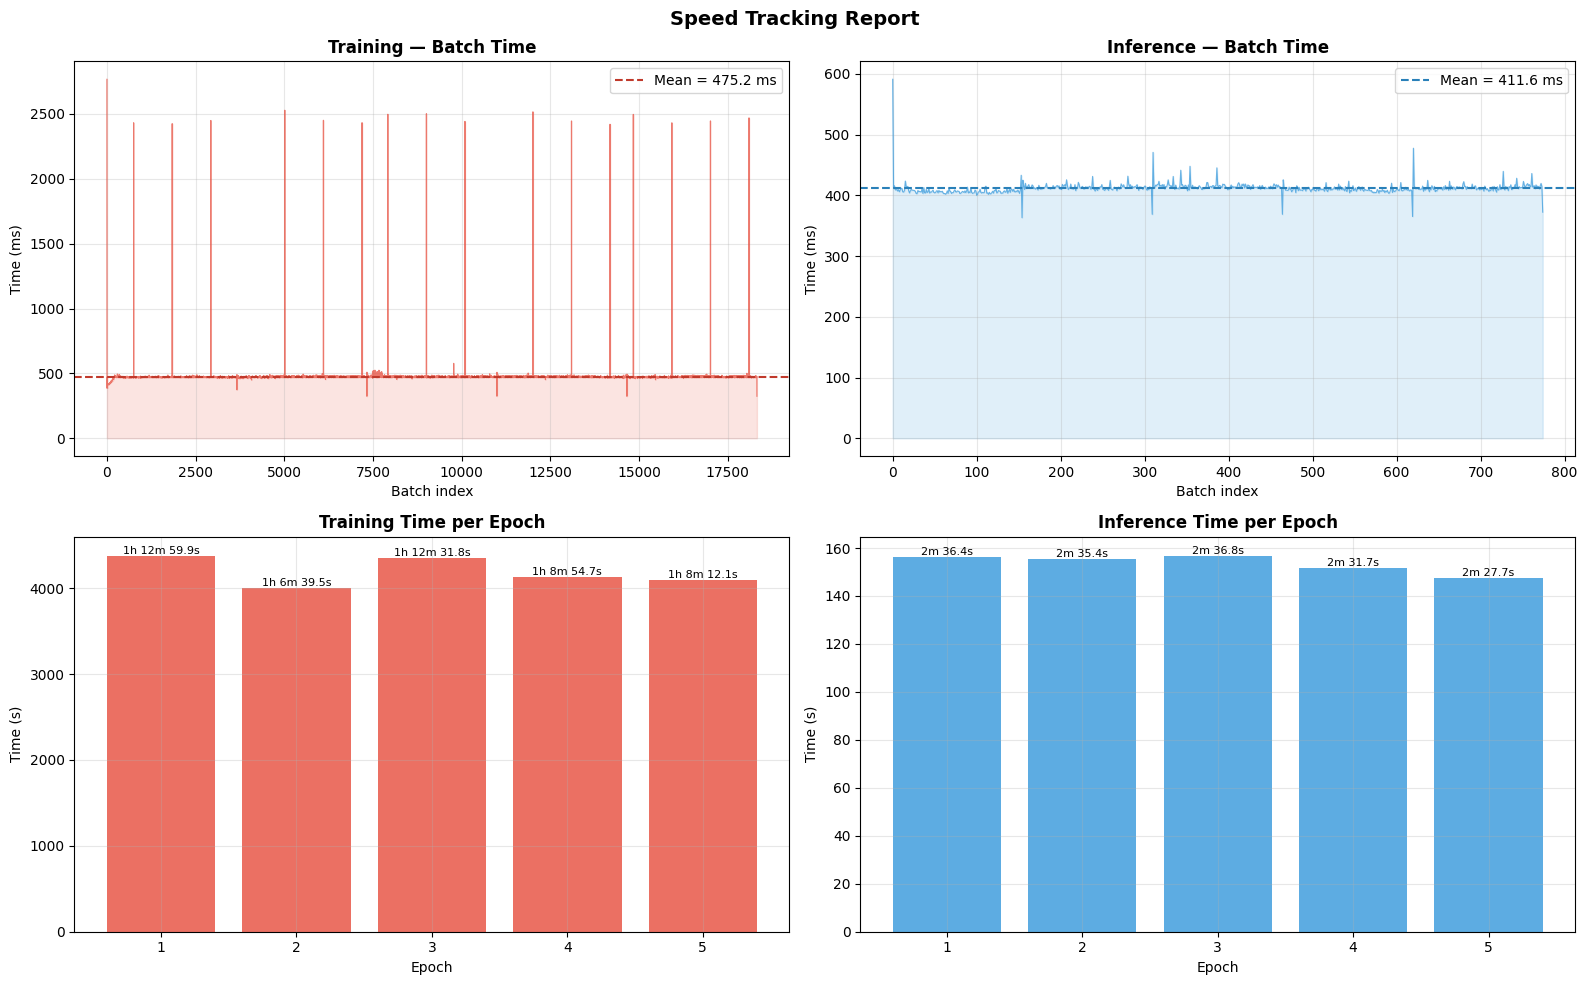

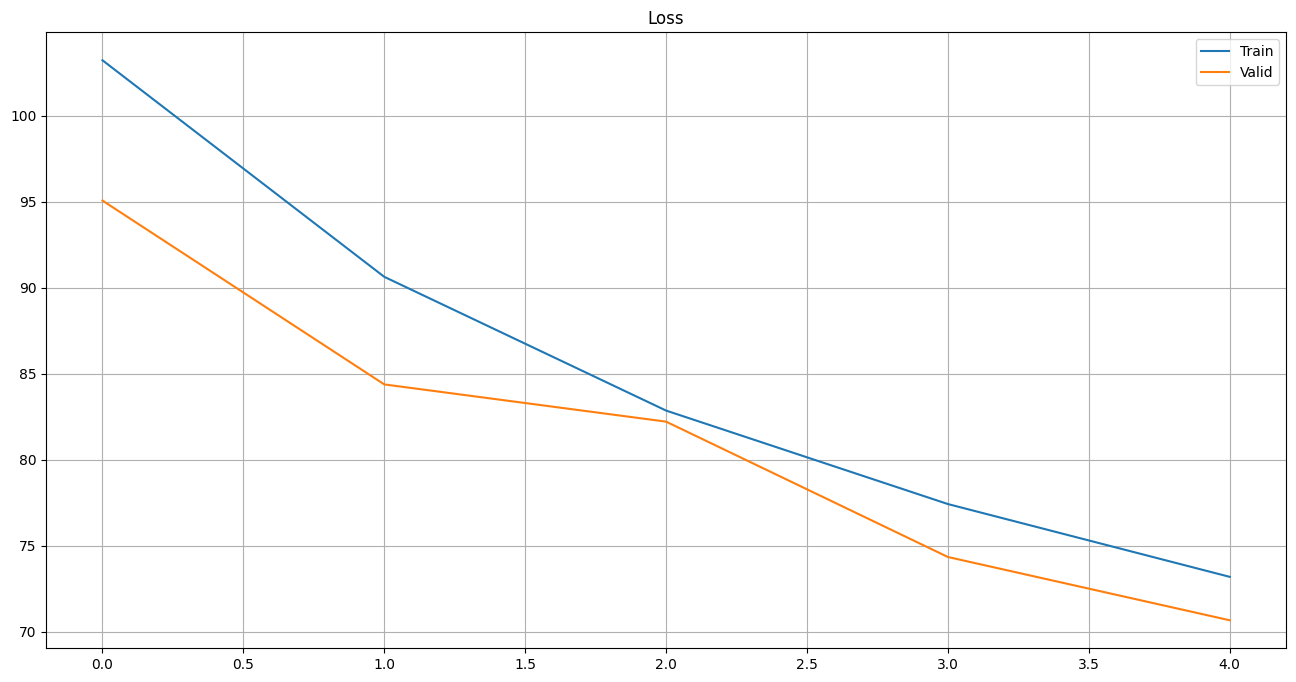

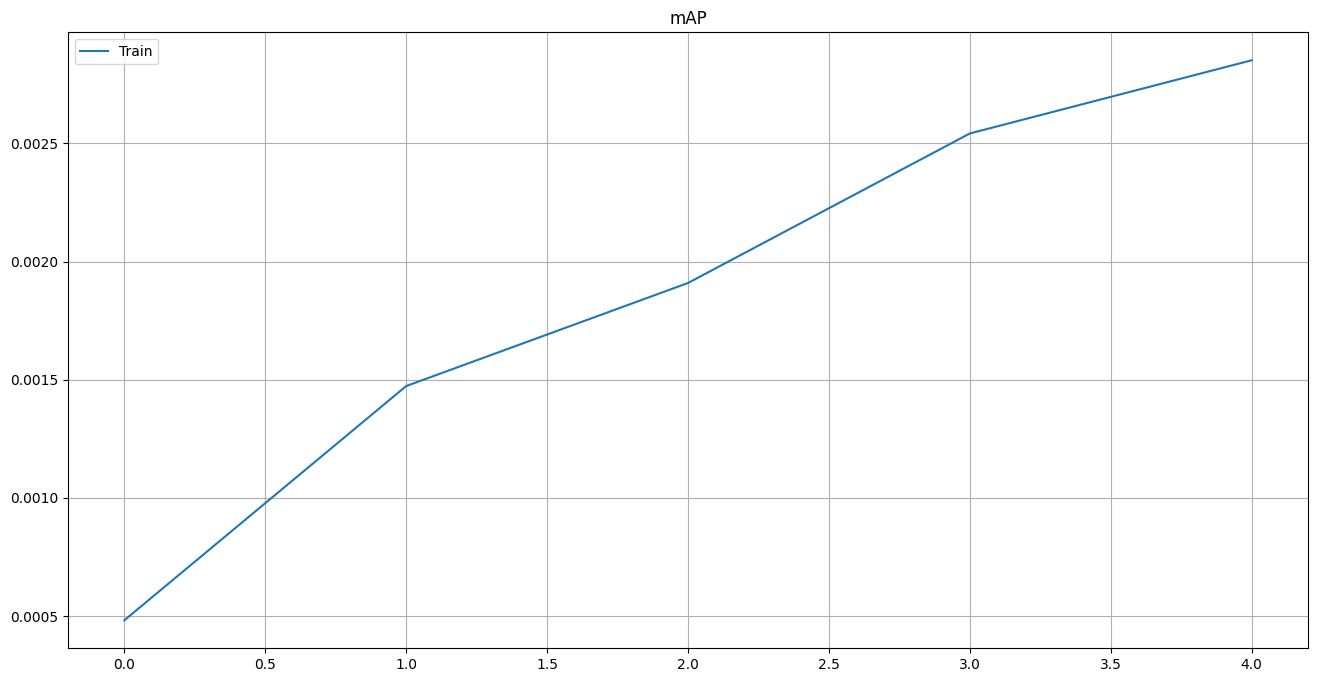

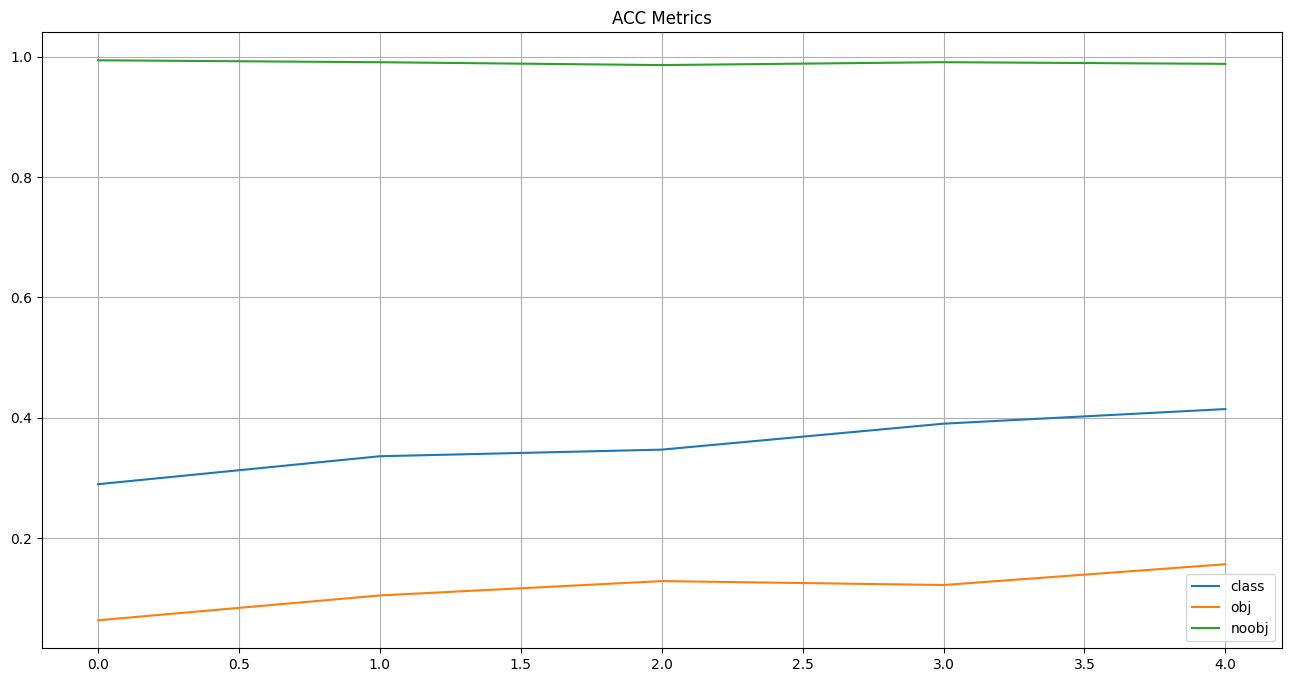

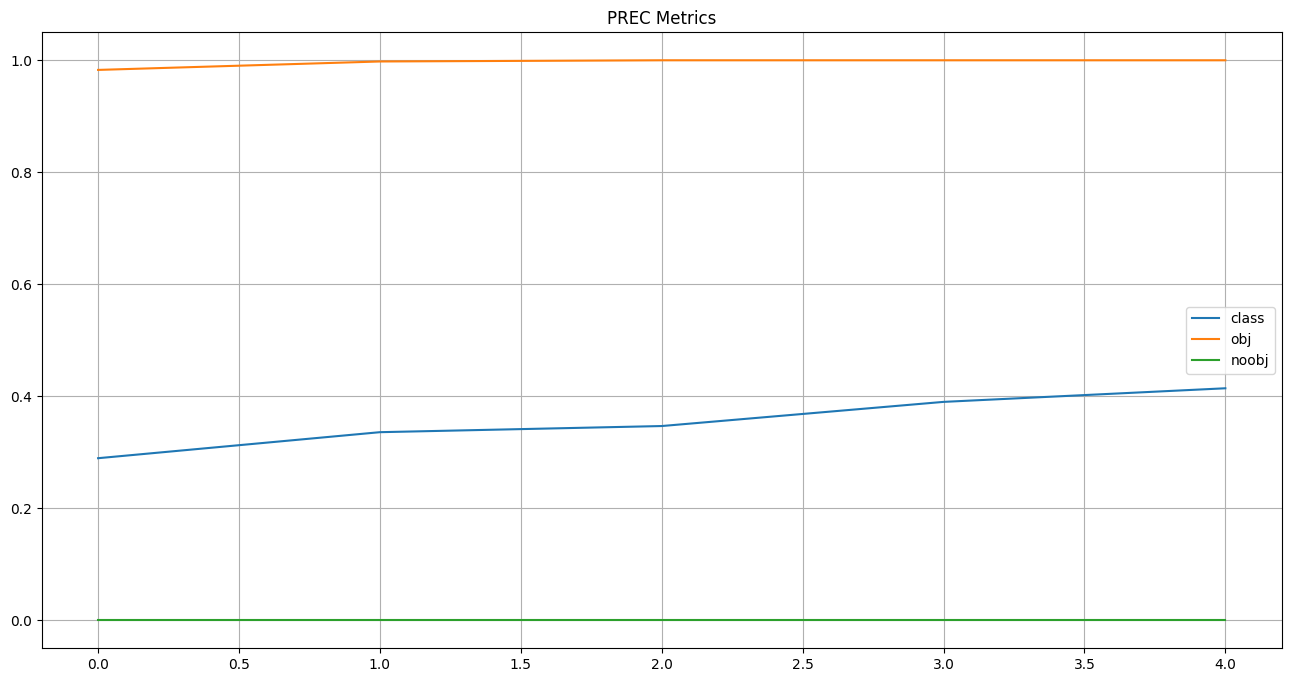

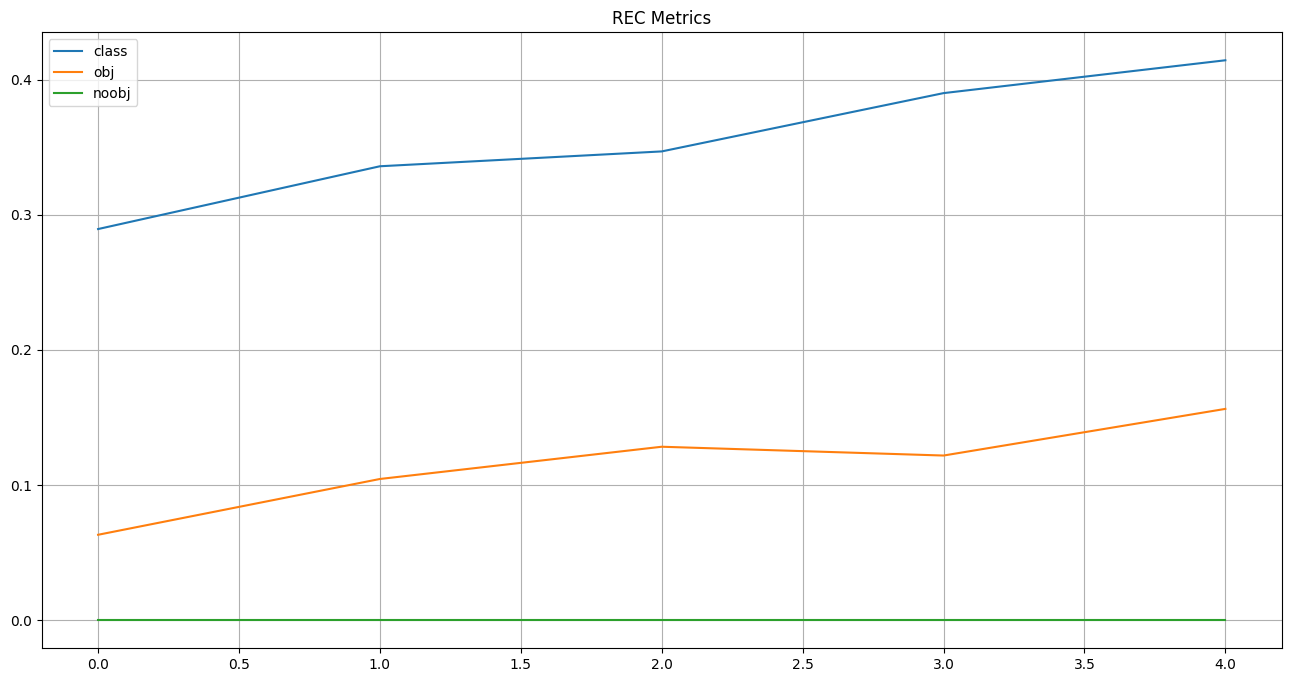


Running dedicated inference benchmark...
Benchmarking inference speed (3 warmup + 50 measured batches)...
  INFERENCE BENCHMARK RESULTS
  Device              : cuda:0
  Batch size          : 32
  Batches measured    : 50
  Mean latency/batch  : 303.83 ms  ± 4.54 ms
  p50 / p95 / p99     : 303.6 / 310.9 / 312.8 ms
  Min / Max           : 295.4 / 312.9 ms
  Throughput          : 105 samples/s
  Latency / sample    : 9.495 ms


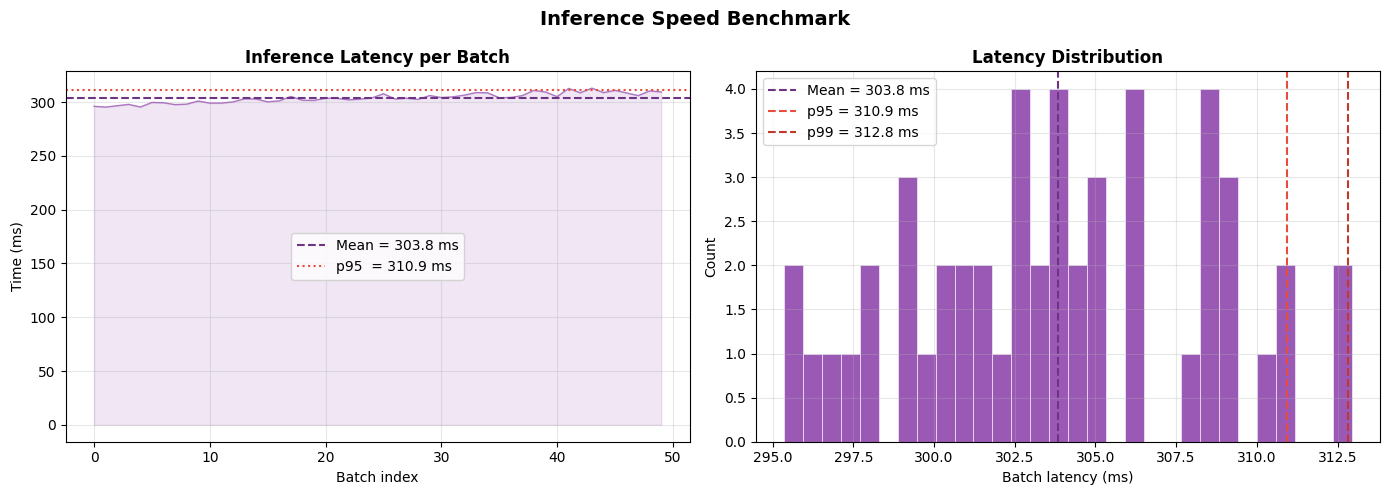

[torch.Size([8, 6]), torch.Size([9, 6]), torch.Size([5, 6]), torch.Size([9, 6]), torch.Size([2, 6]), torch.Size([5, 6]), torch.Size([2, 6]), torch.Size([5, 6]), torch.Size([1, 6]), torch.Size([8, 6]), torch.Size([6, 6]), torch.Size([2, 6]), torch.Size([1, 6]), torch.Size([5, 6]), torch.Size([1, 6]), torch.Size([4, 6]), torch.Size([7, 6]), torch.Size([4, 6]), torch.Size([8, 6]), torch.Size([0, 6]), torch.Size([3, 6]), torch.Size([6, 6]), torch.Size([1, 6]), torch.Size([4, 6]), torch.Size([3, 6]), torch.Size([1, 6]), torch.Size([16, 6]), torch.Size([4, 6]), torch.Size([0, 6]), torch.Size([4, 6]), torch.Size([5, 6]), torch.Size([1, 6])]


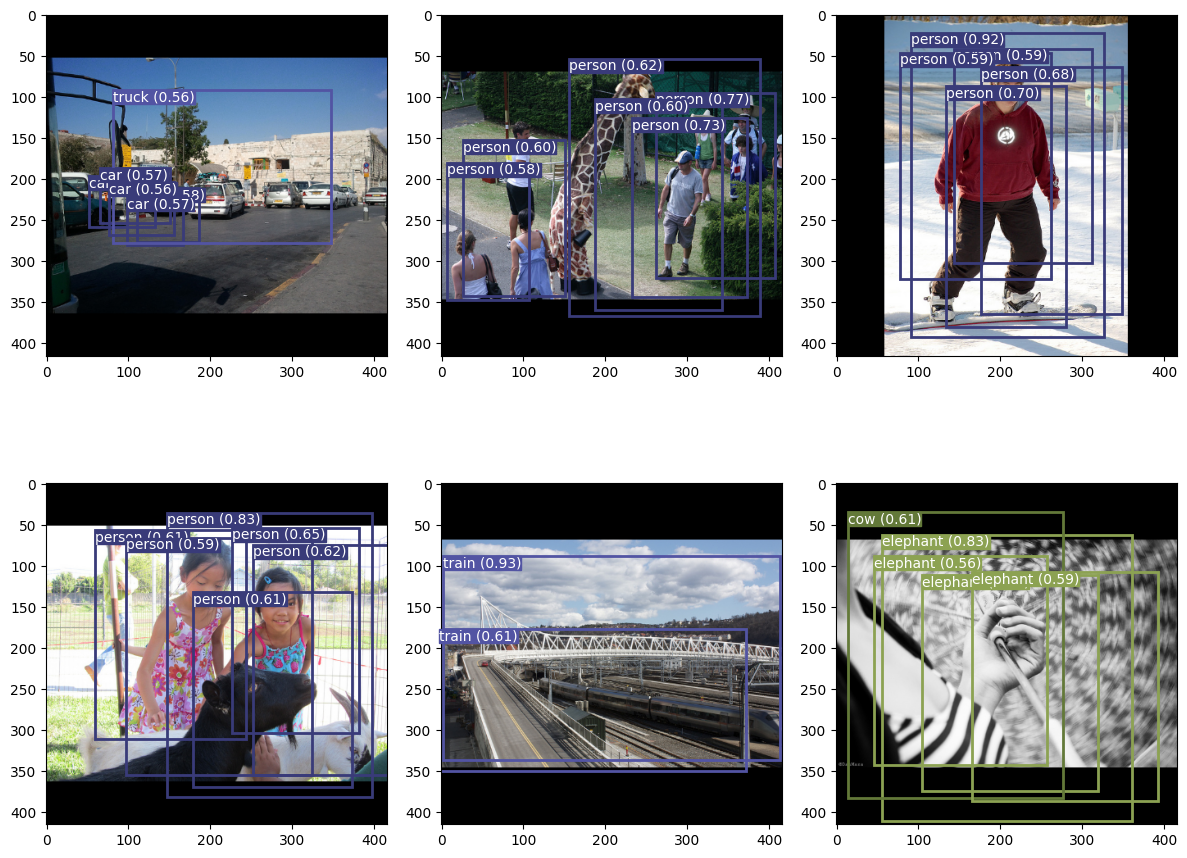


 = 6h 3m 16.1s


In [12]:
'''
import os
os.environ['TORCH_USE_CUDA_DSA'] = '1'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'
'''
main()